# PC1 - Caso C: scouting e inversión en jugadores LATAM U23

**Problema de negocio:** un fondo de inversión deportiva debe decidir qué jugadores latinoamericanos U23 priorizar porque combinan atributos deportivos favorables, margen de desarrollo y un valor de mercado inferior al de perfiles comparables.

**Pregunta central:** ¿qué jugadores latinoamericanos U23 presentan señales de subvaloración y qué posiciones ofrecen mayor potencial de retorno?

| Pregunta analítica | KPI |
|---|---|
| ¿Qué atributos se relacionan con el valor de mercado? | Correlaciones entre atributos FC24 y `log10(valor de mercado)`. |
| ¿Qué jugadores muestran señales de posible subvaloración? | Ratio valor/mediana de pares de la misma posición y banda de `overall`. |
| ¿Qué posiciones muestran mayor valorización histórica? | Mediana del ROI histórico observado a aproximadamente 12 meses. |
| ¿El contraste con estadísticas públicas cambia la priorización? | 60 fichas jugador-partido, fuentes trazables, tasa de cruce y tasas ponderadas por minutos. |

**Pregunta huérfana:** ¿Qué jugadores de la Liga 1 U23 combinan un valor de mercado inferior al de jugadores comparables con un rendimiento real destacado por 90 minutos?**

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import pandas as pd

df = pd.read_csv('/content/male_players.csv')

print("Dimensiones:", df.shape)
display(df.head())

/tmp/ipykernel_588/461054556.py:3: DtypeWarning: Columns (108) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/male_players.csv')


Dimensiones: (180021, 109)


,player_id,player_url,fifa_version,fifa_update,update_as_of,short_name,long_name,player_positions,overall,potential,...,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,gk
0,231747,/player/231747/kylian-mbappe/240002,24.0,2.0,2023-09-22,K. Mbappé,Kylian Mbappé Lottin,"ST, LW",91,94,...,63+3,63+3,63+3,68+3,63+3,54+3,54+3,54+3,63+3,18+3
1,239085,/player/239085/erling-haaland/240002,24.0,2.0,2023-09-22,E. Haaland,Erling Braut Haaland,ST,91,94,...,63+3,63+3,63+3,62+3,60+3,62+3,62+3,62+3,60+3,19+3
2,192985,/player/192985/kevin-de-bruyne/240002,24.0,2.0,2023-09-22,K. De Bruyne,Kevin De Bruyne,"CM, CAM",91,91,...,80+3,80+3,80+3,79+3,75+3,70+3,70+3,70+3,75+3,21+3
3,158023,/player/158023/lionel-messi/240002,24.0,2.0,2023-09-22,L. Messi,Lionel Andrés Messi Cuccittini,"CF, CAM",90,90,...,63+3,63+3,63+3,64+3,59+3,49+3,49+3,49+3,59+3,19+3
4,165153,/player/165153/karim-benzema/240002,24.0,2.0,2023-09-22,K. Benzema,Karim Benzema,"CF, ST",90,90,...,64+3,64+3,64+3,64+3,60+3,55+3,55+3,55+3,60+3,18+3


In [5]:
df.columns.tolist()

['player_id',
 'player_url',
 'fifa_version',
 'fifa_update',
 'update_as_of',
 'short_name',
 'long_name',
 'player_positions',
 'overall',
 'potential',
 'value_eur',
 'wage_eur',
 'age',
 'dob',
 'height_cm',
 'weight_kg',
 'club_team_id',
 'club_name',
 'league_id',
 'league_name',
 'league_level',
 'club_position',
 'club_jersey_number',
 'club_loaned_from',
 'club_joined_date',
 'club_contract_valid_until_year',
 'nationality_id',
 'nationality_name',
 'nation_team_id',
 'nation_position',
 'nation_jersey_number',
 'preferred_foot',
 'weak_foot',
 'skill_moves',
 'international_reputation',
 'work_rate',
 'body_type',
 'real_face',
 'release_clause_eur',
 'player_tags',
 'player_traits',
 'pace',
 'shooting',
 'passing',
 'dribbling',
 'defending',
 'physic',
 'attacking_crossing',
 'attacking_finishing',
 'attacking_heading_accuracy',
 'attacking_short_passing',
 'attacking_volleys',
 'skill_dribbling',
 'skill_curve',
 'skill_fk_accuracy',
 'skill_long_passing',
 'skill_ball_co

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180021 entries, 0 to 180020
Columns: 109 entries, player_id to gk
dtypes: float64(20), int64(43), object(46)
memory usage: 149.7+ MB


In [7]:
print(df['fifa_version'].value_counts().sort_index())
print("Jugadores únicos:", df['player_id'].nunique())

fifa_version
15.0    16182
16.0    16706
17.0    17596
18.0    17954
19.0    18086
20.0    18483
21.0    18892
22.0    19239
23.0    18533
24.0    18350
Name: count, dtype: int64
Jugadores únicos: 53111


In [8]:
df_fc24 = df[df['fifa_version'] == 24.0].copy()

In [9]:
df_fc24[['fifa_update', 'update_as_of']].drop_duplicates()

,fifa_update,update_as_of
0,2.0,2023-09-22


In [10]:
print("Registros FC24:", len(df_fc24))
print("Jugadores únicos FC24:", df_fc24['player_id'].nunique())
print("IDs repetidos:", df_fc24['player_id'].duplicated().sum())

Registros FC24: 18350
Jugadores únicos FC24: 18350
IDs repetidos: 0


In [11]:
print("Nacionalidades distintas:", df_fc24['nationality_name'].nunique())

display(
    df_fc24['nationality_name']
    .value_counts()
    .head(50)
)

Nacionalidades distintas: 160


,count
nationality_name,
England,1615
Germany,1189
Spain,1051
Argentina,970
France,935
Brazil,724
Italy,619
United States,443
Netherlands,432


In [12]:
print("Edad mínima:", df_fc24['age'].min())
print("Edad máxima:", df_fc24['age'].max())

display(
    df_fc24['age']
    .value_counts()
    .sort_index()
)

Edad mínima: 16
Edad máxima: 43


,count
age,
16,25
17,250
18,663
19,1035
20,1280
21,1340
22,1448
23,1512
24,1297


In [13]:
display(
    df_fc24['player_positions']
    .value_counts()
    .head(30)
)

,count
player_positions,
CB,2385
GK,2045
ST,1655
"CDM, CM",937
"CM, CDM",731
CM,618
LB,447
RB,423
"CB, RB",262


In [14]:
paises_latam = [
    'Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia',
    'Costa Rica', 'Cuba', 'Dominican Republic', 'Ecuador',
    'El Salvador', 'Guatemala', 'Honduras', 'Mexico',
    'Nicaragua', 'Panama', 'Paraguay', 'Peru',
    'Uruguay', 'Venezuela'
]

df_latam_u23 = df_fc24[
    (df_fc24['nationality_name'].isin(paises_latam)) &
    (df_fc24['age'] <= 23) &
    (~df_fc24['player_positions'].str.contains('GK', na=False))
].copy()

print("Jugadores LATAM U23 de campo:", len(df_latam_u23))

print("\nPor nacionalidad:")
print(df_latam_u23['nationality_name'].value_counts())

print("\nPor edad:")
print(df_latam_u23['age'].value_counts().sort_index())

Jugadores LATAM U23 de campo: 1070

Por nacionalidad:
nationality_name
Argentina             311
Brazil                171
Colombia               98
Uruguay                81
Paraguay               79
Venezuela              77
Chile                  64
Ecuador                59
Peru                   51
Bolivia                51
Mexico                 15
Costa Rica              5
Dominican Republic      2
Honduras                2
Panama                  2
El Salvador             1
Guatemala               1
Name: count, dtype: int64

Por edad:
age
17     22
18     64
19    127
20    183
21    204
22    208
23    262
Name: count, dtype: int64


In [15]:
tm_players = pd.read_csv('/content/players.csv')
tm_values = pd.read_csv('/content/player_valuations.csv')

print("PLAYERS:", tm_players.shape)
print("VALUATIONS:", tm_values.shape)

PLAYERS: (50149, 26)
VALUATIONS: (656301, 6)


In [16]:
display(tm_players.head())
display(tm_values.head())

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,...,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,1000000.0,30000000.0
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,...,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,750000.0,8000000.0
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,...,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,1000000.0,34500000.0
3,77,NaN,Lúcio,Lúcio,2012,506,lucio,Brazil,Brasília,Brazil,...,NaN,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/lucio/profil/s...,IT1,Juventus FC,200000.0,24500000.0
4,80,Tom,Starke,Tom Starke,2017,27,tom-starke,East Germany (GDR),Freital,Germany,...,IFM,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/tom-starke/pro...,L1,Bayern Munich,100000.0,3000000.0


,player_id,date,market_value_in_eur,current_club_name,current_club_id,player_club_domestic_competition_id
0,405973,2000-01-20,150000,Unknown,3057,BE1
1,342216,2001-07-20,100000,Unknown,1241,SC1
2,3132,2003-12-09,400000,Dynamo Kyiv,126,TR1
3,6893,2003-12-15,900000,Galatasaray,984,GB1
4,10,2004-10-04,7000000,SV Werder Bremen,398,IT1


In [17]:
print("Columnas de players.csv:")
print(tm_players.columns.tolist())

print("\nColumnas de player_valuations.csv:")
print(tm_values.columns.tolist())

Columnas de players.csv:
['player_id', 'first_name', 'last_name', 'name', 'last_season', 'current_club_id', 'player_code', 'country_of_birth', 'city_of_birth', 'country_of_citizenship', 'date_of_birth', 'sub_position', 'position', 'foot', 'height_in_cm', 'contract_expiration_date', 'agent_name', 'image_url', 'international_caps', 'international_goals', 'current_national_team_id', 'url', 'current_club_domestic_competition_id', 'current_club_name', 'market_value_in_eur', 'highest_market_value_in_eur']

Columnas de player_valuations.csv:
['player_id', 'date', 'market_value_in_eur', 'current_club_name', 'current_club_id', 'player_club_domestic_competition_id']


In [18]:
print("=== PLAYERS ===")
print("Filas:", len(tm_players))
print("Jugadores únicos:", tm_players['player_id'].nunique())
print("IDs duplicados:", tm_players['player_id'].duplicated().sum())

print("\n=== VALUATIONS ===")
print("Filas:", len(tm_values))
print("Jugadores únicos con valoración:", tm_values['player_id'].nunique())
print("Periodo de valoraciones:")
print(tm_values['date'].min(), "->", tm_values['date'].max())

=== PLAYERS ===
Filas: 50149
Jugadores únicos: 50149
IDs duplicados: 0

=== VALUATIONS ===
Filas: 656301
Jugadores únicos con valoración: 41528
Periodo de valoraciones:
2000-01-20 -> 2026-06-12


In [19]:
print("Nulos principales en players.csv:")
display(
    tm_players.isna().sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nNulos en player_valuations.csv:")
display(
    tm_values.isna().sum()
    .sort_values(ascending=False)
)

Nulos principales en players.csv:


,0
current_national_team_id,46889
international_caps,30793
international_goals,30793
agent_name,23296
contract_expiration_date,18569
highest_market_value_in_eur,8621
market_value_in_eur,8621
foot,5893
country_of_birth,5885
city_of_birth,5608



Nulos en player_valuations.csv:


,0
player_club_domestic_competition_id,92973
player_id,0
date,0
market_value_in_eur,0
current_club_name,0
current_club_id,0


**Semana 3 - Primeras impresiones de los datasets**

¿Qué tenemos?

FC24 contiene 18,350 jugadores únicos y 109 variables. Dentro del segmento seleccionado se identificaron 1,070 jugadores latinoamericanos U23 de campo. Transfermarkt contiene 50,149 jugadores y 656,301 registros históricos de valorización.

¿Qué nos falta?

Falta comprobar cuántos de los 1,070 jugadores pueden cruzarse correctamente con Transfermarkt y completar el dato propio de enriquecimiento.

¿Qué podemos responder?

Podemos caracterizar a los jugadores según edad, nacionalidad, posición, overall, potential y atributos deportivos, y complementar posteriormente estos perfiles con información histórica de valor de mercado.

¿Qué todavía no podemos responder?

Todavía no podemos determinar qué jugadores están subvalorados ni estimar su potencial de valorización porque falta realizar el cruce entre FC24 y Transfermarkt.


Preguntas que surgen:

¿Qué porcentaje de los 1,070 jugadores podrá vincularse correctamente con Transfermarkt?

¿Qué atributos deportivos se relacionan más con el valor de mercado?

¿Qué jugadores presentan menor valoración frente a perfiles deportivos comparables?

¿Cómo cambia la valorización según posición y trayectoria?

## EDA inicial: perfil, atributos y valor de mercado

En esta sección se analiza la estructura y calidad de FC24 y Transfermarkt. También se incorpora el PBI per cápita del Banco Mundial como contexto de país. El contexto macroeconómico se mantiene separado del desempeño individual.


In [20]:
import pandas as pd

df = pd.read_csv('/content/male_players.csv')
tm_players = pd.read_csv('/content/players.csv')
tm_values = pd.read_csv('/content/player_valuations.csv')

df_fc24 = df[df['fifa_version'] == 24.0].copy()

paises_latam = [
    'Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia',
    'Costa Rica', 'Cuba', 'Dominican Republic', 'Ecuador',
    'El Salvador', 'Guatemala', 'Honduras', 'Mexico',
    'Nicaragua', 'Panama', 'Paraguay', 'Peru',
    'Uruguay', 'Venezuela'
]

df_latam_u23 = df_fc24[
    (df_fc24['nationality_name'].isin(paises_latam)) &
    (df_fc24['age'] <= 23) &
    (~df_fc24['player_positions'].str.contains('GK', na=False))
].copy()

print("Datos cargados correctamente.")

/tmp/ipykernel_588/3520469887.py:3: DtypeWarning: Columns (108) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/male_players.csv')


Datos cargados correctamente.


## Contexto Banco Mundial: PBI per cápita por nacionalidad

La consigna del caso menciona expresamente este contexto. Se consulta el indicador oficial `NY.GDP.PCAP.CD` para 2022-2023 y se conserva el último valor disponible por país. La variable se usa en un gráfico y una correlación exploratoria.

**Pregunta contextual:** ¿existe una asociación descriptiva entre el entorno económico del país de nacionalidad y el valor de mercado observado?


In [21]:
import json
from urllib.parse import urlencode
from urllib.request import urlopen

iso3_por_nacionalidad = {
    'Argentina': 'ARG', 'Bolivia': 'BOL', 'Brazil': 'BRA', 'Chile': 'CHL',
    'Colombia': 'COL', 'Costa Rica': 'CRI', 'Cuba': 'CUB',
    'Dominican Republic': 'DOM', 'Ecuador': 'ECU', 'El Salvador': 'SLV',
    'Guatemala': 'GTM', 'Honduras': 'HND', 'Mexico': 'MEX',
    'Nicaragua': 'NIC', 'Panama': 'PAN', 'Paraguay': 'PRY',
    'Peru': 'PER', 'Uruguay': 'URY', 'Venezuela': 'VEN'
}

codigos_bm = ';'.join(sorted(set(iso3_por_nacionalidad.values())))
parametros_bm = urlencode({
    'date': '2022:2023',
    'format': 'json',
    'per_page': 1000
})
url_bm = (
    f'https://api.worldbank.org/v2/country/{codigos_bm}'
    f'/indicator/NY.GDP.PCAP.CD?{parametros_bm}'
)

with urlopen(url_bm, timeout=30) as respuesta_bm:
    payload_bm = json.load(respuesta_bm)

if not isinstance(payload_bm, list) or len(payload_bm) < 2:
    raise ValueError('La API del Banco Mundial no devolvió el formato esperado.')

registros_bm = [
    {
        'iso3_pais': fila['countryiso3code'],
        'pais_bm': fila['country']['value'],
        'anio_pib': int(fila['date']),
        'pib_per_capita_usd': fila['value']
    }
    for fila in payload_bm[1]
    if fila.get('value') is not None
]

wb_pib = (
    pd.DataFrame(registros_bm)
    .sort_values(['iso3_pais', 'anio_pib'], ascending=[True, False])
    .drop_duplicates('iso3_pais', keep='first')
)

filas_antes_bm = len(df_latam_u23)
df_latam_u23['iso3_pais'] = df_latam_u23['nationality_name'].map(iso3_por_nacionalidad)
df_latam_u23 = df_latam_u23.merge(
    wb_pib,
    on='iso3_pais',
    how='left',
    validate='many_to_one'
)
filas_despues_bm = len(df_latam_u23)
nulos_bm = int(df_latam_u23['pib_per_capita_usd'].isna().sum())
tasa_cruce_bm = 100 * df_latam_u23['pib_per_capita_usd'].notna().mean()

print('Banco Mundial - indicador: NY.GDP.PCAP.CD')
print('Filas antes del merge:', filas_antes_bm)
print('Filas después del merge:', filas_despues_bm)
print('Nulos generados en PBI per cápita:', nulos_bm)
print('Tasa de cruce Banco Mundial:', round(tasa_cruce_bm, 2), '%')
print('Decisión sobre no cruzados: conservarlos con PBI per cápita nulo; no imputar.')
display(wb_pib.sort_values('pib_per_capita_usd', ascending=False))


Banco Mundial - indicador: NY.GDP.PCAP.CD
Filas antes del merge: 1070
Filas después del merge: 1070
Nulos generados en PBI per cápita: 0
Tasa de cruce Banco Mundial: 100.0 %
Decisión sobre no cruzados: conservarlos con PBI per cápita nulo; no imputar.


,iso3_pais,pais_bm,anio_pib,pib_per_capita_usd
32,URY,Uruguay,2023,23378.639973
24,PAN,Panama,2023,18797.193389
10,CRI,Costa Rica,2023,17140.771430
6,CHL,Chile,2023,17081.518074
0,ARG,Argentina,2023,14261.846567
20,MEX,Mexico,2023,13830.843849
12,DOM,Dominican Republic,2023,10630.431744
4,BRA,Brazil,2023,10377.589279
26,PER,Peru,2023,7919.046348
8,COL,Colombia,2023,7012.491691


In [22]:
print("=== FC24 LATAM U23 ===")
print("Filas y columnas:", df_latam_u23.shape)

print("\n=== TRANSFERMARKT - PLAYERS ===")
print("Filas y columnas:", tm_players.shape)

print("\n=== TRANSFERMARKT - VALUATIONS ===")
print("Filas y columnas:", tm_values.shape)

=== FC24 LATAM U23 ===
Filas y columnas: (1070, 113)

=== TRANSFERMARKT - PLAYERS ===
Filas y columnas: (50149, 26)

=== TRANSFERMARKT - VALUATIONS ===
Filas y columnas: (656301, 6)


In [23]:
print("=== NULOS FC24 LATAM U23 ===")
print(df_latam_u23.isnull().sum().sort_values(ascending=False).head(15))

print("\n=== NULOS TRANSFERMARKT - PLAYERS ===")
print(tm_players.isnull().sum().sort_values(ascending=False).head(15))

print("\n=== NULOS TRANSFERMARKT - VALUATIONS ===")
print(tm_values.isnull().sum().sort_values(ascending=False).head(15))

=== NULOS FC24 LATAM U23 ===
goalkeeping_speed                 1070
nation_jersey_number              1062
nation_team_id                    1062
nation_position                   1062
player_tags                       1038
club_loaned_from                   984
player_traits                      730
release_clause_eur                  89
club_joined_date                    89
value_eur                            3
club_team_id                         3
league_level                         3
club_name                            3
club_contract_valid_until_year       3
league_name                          3
dtype: int64

=== NULOS TRANSFERMARKT - PLAYERS ===
current_national_team_id                46889
international_caps                      30793
international_goals                     30793
agent_name                              23296
contract_expiration_date                18569
highest_market_value_in_eur              8621
market_value_in_eur                      8621
foot        

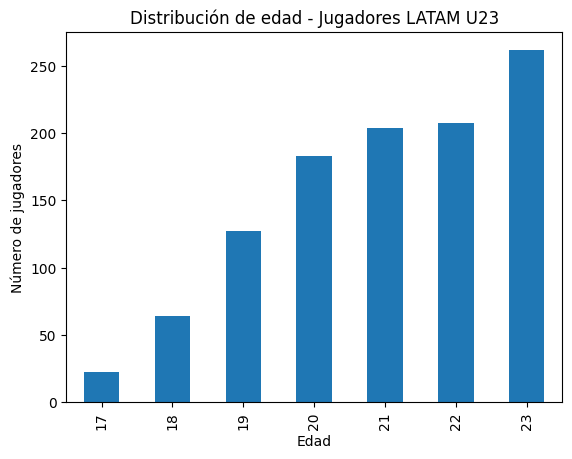

In [24]:
import matplotlib.pyplot as plt

df_latam_u23['age'].value_counts().sort_index().plot(kind='bar')

plt.title('Distribución de edad - Jugadores LATAM U23')
plt.xlabel('Edad')
plt.ylabel('Número de jugadores')
plt.show()

Interpretación: La mayor concentración de jugadores se encuentra entre 21 y 23 años, lo que indica que el universo analizado está compuesto principalmente por futbolistas jóvenes cercanos al límite U23. Esto amplía la cantidad de candidatos potenciales con mayor experiencia competitiva, aunque los jugadores de 17–19 años podrían representar oportunidades de valorización más temprana.

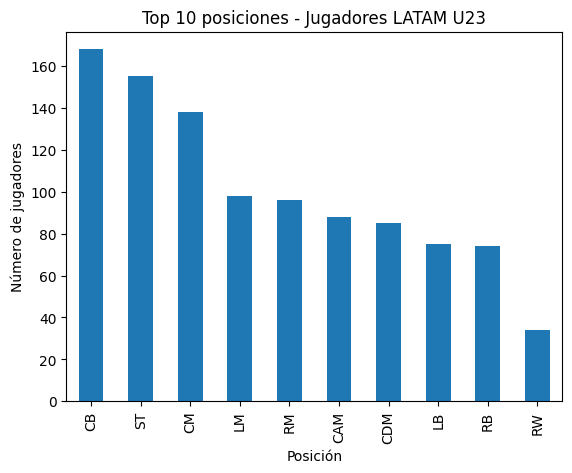

In [25]:
posiciones = df_latam_u23['player_positions'].str.split(',').str[0]

posiciones.value_counts().head(10).plot(kind='bar')

plt.title('Top 10 posiciones - Jugadores LATAM U23')
plt.xlabel('Posición')
plt.ylabel('Número de jugadores')
plt.show()

Interpretación: La muestra presenta una mayor concentración de jugadores en posiciones centrales, especialmente defensa central, delantero y mediocampo. Esto indica que el universo de scouting no está distribuido de manera uniforme por posición, por lo que las comparaciones de valor de mercado y rendimiento deberán realizarse considerando la posición para evitar conclusiones sesgadas.






















Nota: Para esta visualización se utiliza la primera posición registrada en FC24 como posición principal del jugador.

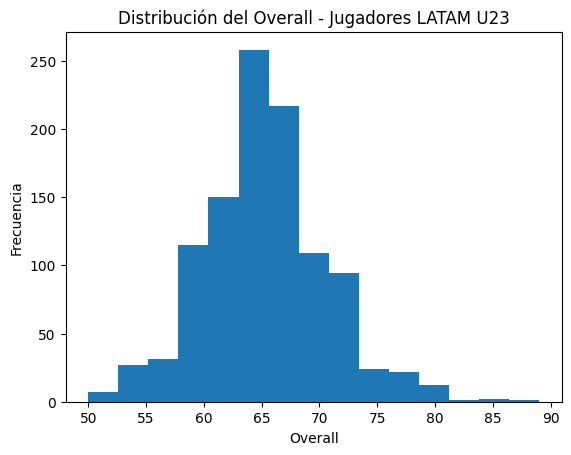

In [26]:
df_latam_u23['overall'].plot(kind='hist', bins=15)

plt.title('Distribución del Overall - Jugadores LATAM U23')
plt.xlabel('Overall')
plt.ylabel('Frecuencia')
plt.show()

Interpretación: La mayoría de los jugadores LATAM U23 presenta un nivel de Overall intermedio, mientras que los jugadores con valoraciones muy altas son poco frecuentes. Esto sugiere que el scouting no debería limitarse únicamente a los jugadores con mayor rendimiento actual, sino también identificar perfiles con margen de desarrollo y potencial de valorización.

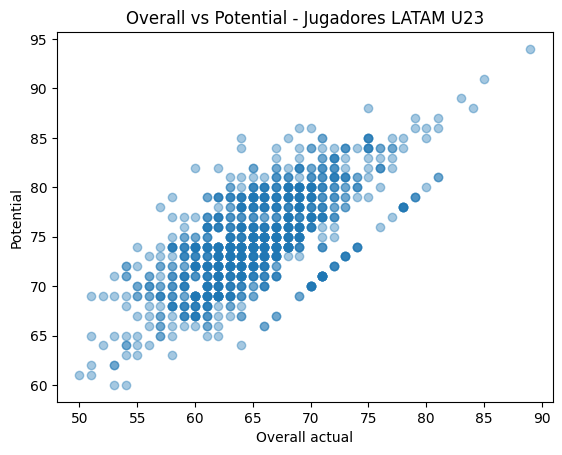

In [27]:
plt.scatter(df_latam_u23['overall'], df_latam_u23['potential'], alpha=0.4)

plt.title('Overall vs Potential - Jugadores LATAM U23')
plt.xlabel('Overall actual')
plt.ylabel('Potential')
plt.show()

Interpretación: Se observa una relación positiva entre el rendimiento actual (overall) y el potencial (potential). Sin embargo, algunos jugadores presentan una brecha amplia entre ambas variables, lo que puede ayudar a identificar perfiles jóvenes con margen de crecimiento y posible valorización futura.

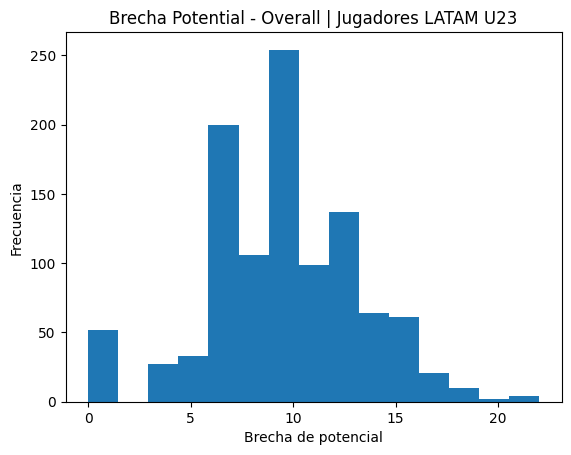

In [28]:
df_latam_u23['potential_gap'] = (
    df_latam_u23['potential'] - df_latam_u23['overall']
)

df_latam_u23['potential_gap'].plot(kind='hist', bins=15)

plt.title('Brecha Potential - Overall | Jugadores LATAM U23')
plt.xlabel('Brecha de potencial')
plt.ylabel('Frecuencia')
plt.show()

Interpretación: La mayoría de los jugadores LATAM U23 presenta un margen de mejora relevante entre su rendimiento actual y su potencial en FC24. Los casos con brechas más altas pueden ser perfiles interesantes para profundizar en el scouting, aunque esta brecha representa potencial deportivo y no necesariamente subvaloración económica.

In [29]:
print(tm_values['market_value_in_eur'].describe())

count    6.563010e+05
mean     2.290093e+06
std      6.721809e+06
min      0.000000e+00
25%      2.000000e+05
50%      5.000000e+05
75%      1.500000e+06
max      2.000000e+08
Name: market_value_in_eur, dtype: float64


In [30]:
print(tm_values.shape)

(656301, 6)


## Distribución del valor de mercado - Transfermarket

Se analiza la distribución de `market_value_in_eur` para conocer cómo se concentran los valores de mercado registrados en Transfermarkt. Debido a la gran diferencia entre los valores mínimos y máximos, se utilizará una transformación logarítmica para visualizar mejor la distribución.

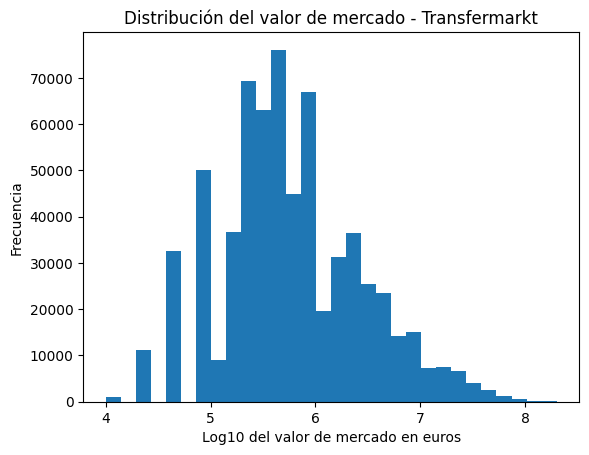

In [31]:
import numpy as np
import matplotlib.pyplot as plt

valores = tm_values[tm_values['market_value_in_eur'] > 0]['market_value_in_eur']

plt.hist(np.log10(valores), bins=30)

plt.title('Distribución del valor de mercado - Transfermarkt')
plt.xlabel('Log10 del valor de mercado en euros')
plt.ylabel('Frecuencia')
plt.show()

Interpretación: Los valores de mercado de Transfermarkt presentan una distribución asimétrica, con una alta concentración en valores bajos y medios y pocos registros con valorizaciones muy elevadas. Por ello, se utiliza una escala logarítmica para representar adecuadamente la distribución y evitar que los valores extremos oculten el comportamiento de la mayoría de los jugadores.

In [32]:
Q1 = tm_values['market_value_in_eur'].quantile(0.25)
Q3 = tm_values['market_value_in_eur'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = tm_values[
    (tm_values['market_value_in_eur'] < limite_inferior) |
    (tm_values['market_value_in_eur'] > limite_superior)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite superior:", limite_superior)
print("Número de outliers:", len(outliers))

Q1: 200000.0
Q3: 1500000.0
IQR: 1300000.0
Límite superior: 3450000.0
Número de outliers: 91386


Interpretación: El criterio IQR identifica como valores atípicos las valorizaciones superiores a €3.45 millones. Sin embargo, estos registros no se eliminarán automáticamente, ya que pueden corresponder a jugadores legítimamente valorizados por encima del resto del mercado. Su presencia confirma la fuerte asimetría de la variable y deberá considerarse en los análisis y modelos posteriores.

In [33]:
variables_corr = [
    'overall',
    'potential',
    'age',
    'pace',
    'shooting',
    'passing',
    'dribbling',
    'defending',
    'physic'
]

correlaciones = df_latam_u23[variables_corr].corr()

print(correlaciones.round(2))

           overall  potential   age  pace  shooting  passing  dribbling  \
overall       1.00       0.71  0.45  0.41      0.39     0.61       0.58   
potential     0.71       1.00 -0.11  0.36      0.26     0.43       0.45   
age           0.45      -0.11  1.00  0.10      0.15     0.25       0.21   
pace          0.41       0.36  0.10  1.00      0.40     0.46       0.63   
shooting      0.39       0.26  0.15  0.40      1.00     0.61       0.77   
passing       0.61       0.43  0.25  0.46      0.61     1.00       0.82   
dribbling     0.58       0.45  0.21  0.63      0.77     0.82       1.00   
defending     0.22       0.11  0.18 -0.22     -0.56     0.02      -0.30   
physic        0.44       0.24  0.29 -0.11     -0.18    -0.06      -0.17   

           defending  physic  
overall         0.22    0.44  
potential       0.11    0.24  
age             0.18    0.29  
pace           -0.22   -0.11  
shooting       -0.56   -0.18  
passing         0.02   -0.06  
dribbling      -0.30   -0.17  
d

Interpretación de correlaciones:
Se observa una correlación positiva alta entre overall y potential (0.71). Asimismo, overall presenta relaciones positivas con passing (0.61), dribbling (0.58), age (0.45) y physic (0.44). También destaca la relación entre passing y dribbling (0.82). Por otro lado, algunas correlaciones negativas, como shooting y defending (-0.56), pueden estar asociadas a las diferencias de perfil entre posiciones. Estas relaciones permiten conocer la estructura de los atributos deportivos antes de construir los modelos posteriores y no implican causalidad.

## Revisión de duplicados

Se revisa la presencia de registros duplicados en FC24 y Transfermarkt como parte del control de calidad de los datos antes de realizar los cruces y análisis posteriores.


In [34]:
print("Duplicados exactos FC24 LATAM U23:",
      df_latam_u23.duplicated().sum())

print("Duplicados exactos Transfermarkt players:",
      tm_players.duplicated().sum())

print("Duplicados exactos Transfermarkt valuations:",
      tm_values.duplicated().sum())

Duplicados exactos FC24 LATAM U23: 0
Duplicados exactos Transfermarkt players: 0
Duplicados exactos Transfermarkt valuations: 0


Interpretación: No se identificaron registros duplicados exactos en FC24 LATAM U23, Transfermarkt players ni Transfermarkt valuations. Por ello, no se requiere eliminar observaciones por duplicación exacta en esta etapa. En el caso de player_valuations, la existencia de múltiples registros por jugador corresponde a distintas fechas de valorización y no debe confundirse con duplicados.

In [35]:
print("Valores de mercado iguales a 0:",
      (tm_values['market_value_in_eur'] == 0).sum())

print("Valores de mercado negativos:",
      (tm_values['market_value_in_eur'] < 0).sum())

Valores de mercado iguales a 0: 1
Valores de mercado negativos: 0


Interpretación: Se identificó un único registro con valor de mercado igual a cero y no se encontraron valores negativos. El registro con valor cero deberá excluirse de análisis que requieran transformaciones logarítmicas o modelamiento del valor de mercado, ya que log(0) no está definido. No se detectaron valores negativos que requieran tratamiento adicional.

Revisión de valores faltantes en variables analíticas

Se revisan los valores faltantes únicamente en las variables seleccionadas para el análisis de jugadores LATAM U23, con el fin de determinar si requieren tratamiento antes de los análisis posteriores.

In [36]:
variables_clave = [
    'age',
    'overall',
    'potential',
    'pace',
    'shooting',
    'passing',
    'dribbling',
    'defending',
    'physic'
]

print(df_latam_u23[variables_clave].isnull().sum())

age          0
overall      0
potential    0
pace         0
shooting     0
passing      0
dribbling    0
defending    0
physic       0
dtype: int64


Interpretación: Las variables analíticas seleccionadas no presentan valores faltantes en el subconjunto de jugadores LATAM U23. Por ello, no se requiere aplicar técnicas de imputación ni eliminar observaciones por datos ausentes en estas variables, lo que permite continuar con los análisis posteriores sin introducir modificaciones en esta etapa.

## Preparación del cruce FC24 - Transfermarkt

Se identifican las variables disponibles en ambas fuentes que servirán para vincular a los jugadores antes de aplicar la normalización de nombres y el fuzzy matching.

In [37]:
print("FC24:")
print(df_latam_u23[
    ['long_name', 'dob', 'nationality_name', 'club_name', 'player_positions']
].head())

print("\nTransfermarkt:")
print(tm_players[
    ['name', 'date_of_birth', 'country_of_citizenship', 'current_club_name', 'position']
].head())

FC24:
                                 long_name         dob nationality_name  \
0  Vinícius José Paixão de Oliveira Júnior  2000-07-12           Brazil   
1                    Rodrygo Silva de Goes  2001-01-09           Brazil   
2         Gabriel Teodoro Martinelli Silva  2001-06-18           Brazil   
3                  Enzo Jeremías Fernández  2001-01-17        Argentina   
4                Antony Matheus dos Santos  2000-02-24           Brazil   

           club_name player_positions  
0        Real Madrid               LW  
1        Real Madrid       RW, LW, ST  
2            Arsenal           LW, LM  
3            Chelsea          CM, CDM  
4  Manchester United           RW, RM  

Transfermarkt:
                 name        date_of_birth country_of_citizenship  \
0      Miroslav Klose  1978-06-09 00:00:00                Germany   
1  Roman Weidenfeller  1980-08-06 00:00:00                Germany   
2    Dimitar Berbatov  1981-01-30 00:00:00               Bulgaria   
3          

## Normalización de nombres y fechas

Para facilitar el cruce entre FC24 y Transfermarkt, se normalizan los nombres eliminando diferencias de mayúsculas, tildes y caracteres especiales. También se estandarizan las fechas de nacimiento. La fecha de nacimiento se utilizará como variable auxiliar de alta precisión para validar las coincidencias.

In [38]:
import re
import unicodedata

def normalizar_nombre(texto):
    if pd.isna(texto):
        return ''

    texto = str(texto).lower().strip()
    texto = ''.join(
        c for c in unicodedata.normalize('NFD', texto)
        if unicodedata.category(c) != 'Mn'
    )
    texto = re.sub(r'[^a-z0-9 ]', ' ', texto)
    texto = re.sub(r'\s+', ' ', texto).strip()

    return texto


df_latam_u23['nombre_norm'] = df_latam_u23['long_name'].apply(normalizar_nombre)
tm_players['nombre_norm'] = tm_players['name'].apply(normalizar_nombre)

df_latam_u23['dob_norm'] = pd.to_datetime(
    df_latam_u23['dob'], errors='coerce'
).dt.date

tm_players['dob_norm'] = pd.to_datetime(
    tm_players['date_of_birth'], errors='coerce'
).dt.date

print(df_latam_u23[['long_name', 'nombre_norm', 'dob_norm']].head())
print()
print(tm_players[['name', 'nombre_norm', 'dob_norm']].head())

                                 long_name  \
0  Vinícius José Paixão de Oliveira Júnior   
1                    Rodrygo Silva de Goes   
2         Gabriel Teodoro Martinelli Silva   
3                  Enzo Jeremías Fernández   
4                Antony Matheus dos Santos   

                               nombre_norm    dob_norm  
0  vinicius jose paixao de oliveira junior  2000-07-12  
1                    rodrygo silva de goes  2001-01-09  
2         gabriel teodoro martinelli silva  2001-06-18  
3                  enzo jeremias fernandez  2001-01-17  
4                antony matheus dos santos  2000-02-24  

                 name         nombre_norm    dob_norm
0      Miroslav Klose      miroslav klose  1978-06-09
1  Roman Weidenfeller  roman weidenfeller  1980-08-06
2    Dimitar Berbatov    dimitar berbatov  1981-01-30
3               Lúcio               lucio  1978-05-08
4          Tom Starke          tom starke  1981-03-18


## Matching exacto por nombre y fecha de nacimiento

Se realiza un primer cruce conservador utilizando el nombre normalizado y la fecha de nacimiento. Esta combinación permite identificar coincidencias de alta precisión antes de recurrir al fuzzy matching para los jugadores restantes.

In [39]:
match_exacto = df_latam_u23.merge(
    tm_players[
        ['player_id', 'name', 'nombre_norm', 'dob_norm',
         'country_of_citizenship', 'current_club_name', 'position']
    ],
    on=['nombre_norm', 'dob_norm'],
    how='left',
    suffixes=('_fc24', '_tm')
)

print("Jugadores FC24 LATAM U23:", len(df_latam_u23))

print("Matches exactos encontrados:",
      match_exacto['player_id_tm'].notna().sum())

print("Tasa de match exacto:",
      round(match_exacto['player_id_tm'].notna().sum() / len(df_latam_u23) * 100, 2), "%")

Jugadores FC24 LATAM U23: 1070
Matches exactos encontrados: 140
Tasa de match exacto: 13.08 %


Interpretación: El matching exacto por nombre normalizado y fecha de nacimiento identificó 140 coincidencias entre los 1,070 jugadores LATAM U23 de FC24, equivalente a una tasa inicial de 13.08 %. Esta tasa corresponde únicamente a coincidencias exactas y no representa la tasa final de integración. Los jugadores restantes serán evaluados mediante fuzzy matching y variables auxiliares para capturar diferencias en la forma de registrar los nombres entre las fuentes.

In [40]:
print("Filas después del merge:", len(match_exacto))

print("Jugadores FC24 únicos en el merge:",
      match_exacto['player_id_fc24'].nunique())

print("Jugadores FC24 repetidos por el merge:",
      match_exacto['player_id_fc24'].duplicated().sum())

Filas después del merge: 1070
Jugadores FC24 únicos en el merge: 1070
Jugadores FC24 repetidos por el merge: 0


Control del merge: El cruce exacto conserva los 1,070 jugadores originales de FC24 y no genera registros duplicados. Por lo tanto, la integración por nombre normalizado y fecha de nacimiento no produjo multiplicación de filas y puede utilizarse como base para continuar con el fuzzy matching de los jugadores no coincidentes.


## Fuzzy matching de jugadores no coincidentes

Para los jugadores que no coincidieron mediante nombre exacto y fecha de nacimiento, se buscará el nombre más similar dentro de Transfermarkt entre candidatos con la misma fecha de nacimiento. El puntaje de similitud se utilizará posteriormente para definir coincidencias automáticas y casos que requieran revisión manual.


In [41]:
!pip -q install rapidfuzz

from rapidfuzz import fuzz, process

no_match = match_exacto[
    match_exacto['player_id_tm'].isna()
].copy()

tm_por_dob = {
    fecha: grupo
    for fecha, grupo in tm_players[
        tm_players['dob_norm'].notna()
    ].groupby('dob_norm')
}

def buscar_candidato(row):
    fecha = row['dob_norm']

    if fecha not in tm_por_dob:
        return pd.Series([pd.NA, pd.NA, 0])

    candidatos = tm_por_dob[fecha]

    resultado = process.extractOne(
        row['nombre_norm'],
        candidatos['nombre_norm'],
        scorer=fuzz.token_set_ratio
    )

    if resultado is None:
        return pd.Series([pd.NA, pd.NA, 0])

    _, score, indice = resultado
    candidato = candidatos.loc[indice]

    return pd.Series([
        candidato['player_id'],
        candidato['name'],
        round(score, 2)
    ])

no_match[
    ['player_id_tm_candidato', 'nombre_tm_candidato', 'score_fuzzy']
] = no_match.apply(buscar_candidato, axis=1)

print("Jugadores sin match exacto:", len(no_match))

print("Candidatos con score >= 90:",
      (no_match['score_fuzzy'] >= 90).sum())

print("Candidatos con score entre 80 y 89.99:",
      ((no_match['score_fuzzy'] >= 80) &
       (no_match['score_fuzzy'] < 90)).sum())

print("Candidatos con score < 80:",
      (no_match['score_fuzzy'] < 80).sum())

Jugadores sin match exacto: 930
Candidatos con score >= 90: 413
Candidatos con score entre 80 y 89.99: 2
Candidatos con score < 80: 515


## Auditoría de candidatos fuzzy de alta similitud

Se revisa una muestra de candidatos con similitud igual o superior a 90 para comprobar que el fuzzy matching está identificando correctamente al mismo jugador antes de aceptar automáticamente estas coincidencias.

In [42]:
auditoria_alta = no_match[
    no_match['score_fuzzy'] >= 90
][[
    'long_name',
    'dob_norm',
    'nationality_name',
    'player_positions',
    'player_id_tm_candidato',
    'nombre_tm_candidato',
    'score_fuzzy'
]].sample(10, random_state=42)

auditoria_alta = auditoria_alta.merge(
    tm_players[
        ['player_id',
         'country_of_citizenship',
         'position',
         'current_club_name']
    ],
    left_on='player_id_tm_candidato',
    right_on='player_id',
    how='left'
)

print(
    auditoria_alta[
        [
            'long_name',
            'dob_norm',
            'nationality_name',
            'country_of_citizenship',
            'player_positions',
            'position',
            'nombre_tm_candidato',
            'score_fuzzy'
        ]
    ].to_string(index=False)
)

                     long_name   dob_norm nationality_name country_of_citizenship player_positions position nombre_tm_candidato  score_fuzzy
 Carlos Miguel Paraco González 2003-10-27        Venezuela              Venezuela               LM   Attack       Carlos Paraco        100.0
          Matías Galarza Fonda 2002-02-11         Paraguay               Paraguay          CM, CAM Midfield      Matías Galarza        100.0
      Shean Paul Barbosa Gómez 2004-04-07         Colombia               Colombia               LB Defender       Shean Barbosa        100.0
    Diego Ariel Duarte Garcete 2002-04-08         Paraguay               Paraguay               ST   Attack        Diego Duarte        100.0
         Ferreira Soares Adson 2000-10-06           Brazil                 Brazil          RM, CAM   Attack               Adson        100.0
Benjamín Ignacio Rojas Ferrera 2001-03-01            Chile                  Chile           CB, RB Defender      Benjamín Rojas        100.0
Pedro Henriqu

In [43]:
alta_todos = no_match[
    no_match['score_fuzzy'] >= 90
][[
    'long_name',
    'dob_norm',
    'nationality_name',
    'player_id_tm_candidato',
    'nombre_tm_candidato',
    'score_fuzzy'
]].copy()

alta_todos = alta_todos.merge(
    tm_players[
        ['player_id', 'country_of_citizenship']
    ],
    left_on='player_id_tm_candidato',
    right_on='player_id',
    how='left'
)

alta_todos['nac_fc24_norm'] = alta_todos['nationality_name'].apply(normalizar_nombre)
alta_todos['nac_tm_norm'] = alta_todos['country_of_citizenship'].apply(normalizar_nombre)

alta_todos['misma_nacionalidad'] = (
    alta_todos['nac_fc24_norm'] == alta_todos['nac_tm_norm']
)

print("Candidatos con score >= 90:", len(alta_todos))
print("Con score 100:", (alta_todos['score_fuzzy'] == 100).sum())
print("Con score entre 90 y 99.99:",
      ((alta_todos['score_fuzzy'] >= 90) &
       (alta_todos['score_fuzzy'] < 100)).sum())

print("Nacionalidad coincide:",
      alta_todos['misma_nacionalidad'].sum())

print("Nacionalidad no coincide:",
      (~alta_todos['misma_nacionalidad']).sum())

Candidatos con score >= 90: 413
Con score 100: 410
Con score entre 90 y 99.99: 3
Nacionalidad coincide: 406
Nacionalidad no coincide: 7


In [44]:
casos_nacionalidad_distinta = alta_todos[
    alta_todos['misma_nacionalidad'] == False
][[
    'long_name',
    'dob_norm',
    'nationality_name',
    'nombre_tm_candidato',
    'country_of_citizenship',
    'score_fuzzy'
]]

print(casos_nacionalidad_distinta.to_string(index=False))

                 long_name   dob_norm nationality_name nombre_tm_candidato country_of_citizenship  score_fuzzy
      Facundo Tomás Garcés 1999-09-05        Argentina      Facundo Garcés               Malaysia        100.0
   Erik Jorgens de Menezes 2001-02-18           Brazil                Erik   United Arab Emirates        100.0
   Franco Zanelatto Téllez 2000-05-09         Paraguay    Franco Zanelatto                   Peru        100.0
Lucas Gabriel Monzón Lemos 2001-09-29           Brazil        Lucas Monzón                Uruguay        100.0
          Hevertton Santos 2001-02-01           Brazil           Hevertton               Portugal        100.0
     Jonathan Germán Gómez 2003-09-01           Mexico      Jonathan Gómez          United States        100.0
 Tobías Ariel Cervera Cadi 2002-08-06        Argentina      Tobías Cervera                  Syria        100.0


In [45]:
casos_90_99 = no_match[
    (no_match['score_fuzzy'] >= 90) &
    (no_match['score_fuzzy'] < 100)
][[
    'long_name',
    'dob_norm',
    'nationality_name',
    'nombre_tm_candidato',
    'score_fuzzy'
]]

print(casos_90_99.to_string(index=False))

                      long_name   dob_norm nationality_name   nombre_tm_candidato  score_fuzzy
Cristian Sleiker Cásseres Yepes 2000-01-20        Venezuela Cristian Cásseres Jr.        91.89
             Benjamín Domínguez 2003-09-19        Argentina       Benja Domínguez        90.91
               Ronaldo De Jesús 2001-04-21         Paraguay       Ronaldo Dejesús        96.77


Match de alta confianza = misma fecha de nacimiento + score fuzzy ≥ 90.
La nacionalidad se usa como control auxiliar, pero no como condición obligatoria porque puede haber doble nacionalidad o diferencias de registro.

Regla de matching de alta confianza - Etapa 1:

 Se aceptan como coincidencias de alta confianza los jugadores con la misma fecha de nacimiento y un score_fuzzy igual o superior a 90. La nacionalidad se utiliza como variable auxiliar de validación, pero no como requisito obligatorio debido a posibles casos de doble nacionalidad o diferencias entre fuentes. Con esta regla se identifican 553 jugadores vinculados entre FC24 y Transfermarkt, equivalentes al 51.68% del universo LATAM U23.

In [46]:
restantes = no_match[
    no_match['score_fuzzy'] < 90
].copy()

print("Jugadores restantes:", len(restantes))

print("Sin candidato con misma fecha de nacimiento:",
      (restantes['score_fuzzy'] == 0).sum())

print("Con candidato, pero score menor a 90:",
      ((restantes['score_fuzzy'] > 0) &
       (restantes['score_fuzzy'] < 90)).sum())

Jugadores restantes: 517
Sin candidato con misma fecha de nacimiento: 1
Con candidato, pero score menor a 90: 516


In [47]:
print("Score 80 a 89.99:",
      ((restantes['score_fuzzy'] >= 80) &
       (restantes['score_fuzzy'] < 90)).sum())

print("Score 70 a 79.99:",
      ((restantes['score_fuzzy'] >= 70) &
       (restantes['score_fuzzy'] < 80)).sum())

print("Score 60 a 69.99:",
      ((restantes['score_fuzzy'] >= 60) &
       (restantes['score_fuzzy'] < 70)).sum())

print("Score menor a 60:",
      (restantes['score_fuzzy'] < 60).sum())


Score 80 a 89.99: 2
Score 70 a 79.99: 6
Score 60 a 69.99: 10
Score menor a 60: 499


In [48]:
restantes_aux = restantes.copy()

restantes_aux['nac_norm'] = (
    restantes_aux['nationality_name']
    .apply(normalizar_nombre)
)

tm_players['nac_norm'] = (
    tm_players['country_of_citizenship']
    .apply(normalizar_nombre)
)

candidatos_dob_nac = restantes_aux[
    ['player_id_fc24', 'long_name', 'dob_norm', 'nac_norm']
].merge(
    tm_players[
        ['player_id', 'name', 'dob_norm', 'nac_norm']
    ],
    on=['dob_norm', 'nac_norm'],
    how='left'
)

conteo_candidatos = (
    candidatos_dob_nac
    .groupby('player_id_fc24')['player_id']
    .count()
)

print("Con 1 único candidato por fecha + nacionalidad:",
      (conteo_candidatos == 1).sum())

print("Con más de 1 candidato:",
      (conteo_candidatos > 1).sum())

print("Sin candidato:",
      (conteo_candidatos == 0).sum())

Con 1 único candidato por fecha + nacionalidad: 52
Con más de 1 candidato: 14
Sin candidato: 451


In [49]:
unico_candidato = candidatos_dob_nac[
    candidatos_dob_nac['player_id_fc24'].isin(
        conteo_candidatos[conteo_candidatos == 1].index
    )
].copy()

muestra_unicos = unico_candidato[
    ['long_name', 'dob_norm', 'nac_norm', 'name']
].sample(10, random_state=42)

print(muestra_unicos.to_string(index=False))

                   long_name   dob_norm  nac_norm                 name
        Agostino Luigi Spina 2001-10-31 argentina         Aarón Quirós
        Lucas Nahuel Naranjo 2001-11-21 argentina Santiago Ramos Mingo
Vitor Hugo Ferreira Oliveira 2003-03-25    brazil              Vitinho
        Brian Lautaro Guzmán 2000-01-18 argentina  Jonathan Dellarossa
            Valentín Pereyra 2002-04-18 argentina         Gabriel Vega
           Bernardo de Souza 2001-02-06    brazil                Natan
       Alexis Amadeo Sabella 2001-06-20 argentina        Alejo Tabares
        Elio Nicolas Firmino 2001-01-30    brazil             Zanocelo
  William Joel Pacho Tenorio 2001-10-16   ecuador        Willian Pacho
  David Samuel Custódio Lima 2000-02-20    brazil               Pastor


In [50]:
print(
    df_latam_u23[
        ['long_name', 'short_name', 'dob']
    ].head(15).to_string(index=False)
)

                              long_name         short_name        dob
Vinícius José Paixão de Oliveira Júnior           Vini Jr. 2000-07-12
                  Rodrygo Silva de Goes            Rodrygo 2001-01-09
       Gabriel Teodoro Martinelli Silva Gabriel Martinelli 2001-06-18
                Enzo Jeremías Fernández       E. Fernández 2001-01-17
              Antony Matheus dos Santos             Antony 2000-02-24
                  Manuel Ugarte Ribeiro          M. Ugarte 2001-04-11
         Rosival Jailson Dourado Santos    Rosival Dourado 2000-02-29
         Welington Kauê Dano Nascimento     Welington Dano 2000-02-29
                         Julián Álvarez         J. Álvarez 2000-01-31
            Moisés Isaac Caicedo Corozo         M. Caicedo 2001-11-02
         Laureano Thomas Santeiro Marre     Laure Santeiro 2000-02-29
                 Thiago Ezequiel Almada          T. Almada 2001-04-26
            Piero Martín Hincapié Reyna        P. Hincapié 2002-01-09
         Ronaldo Die

In [51]:
restantes['short_name_norm'] = (
    restantes['short_name'].apply(normalizar_nombre)
)

def buscar_candidato_short(row):
    fecha = row['dob_norm']

    if fecha not in tm_por_dob:
        return pd.Series([pd.NA, pd.NA, 0])

    candidatos = tm_por_dob[fecha]

    resultado = process.extractOne(
        row['short_name_norm'],
        candidatos['nombre_norm'],
        scorer=fuzz.token_set_ratio
    )

    if resultado is None:
        return pd.Series([pd.NA, pd.NA, 0])

    _, score, indice = resultado
    candidato = candidatos.loc[indice]

    return pd.Series([
        candidato['player_id'],
        candidato['name'],
        round(score, 2)
    ])

restantes[
    ['player_id_tm_short', 'nombre_tm_short', 'score_short']
] = restantes.apply(buscar_candidato_short, axis=1)

print("Restantes analizados:", len(restantes))
print("Short name con score >= 90:",
      (restantes['score_short'] >= 90).sum())
print("Short name con score 80 a 89.99:",
      ((restantes['score_short'] >= 80) &
       (restantes['score_short'] < 90)).sum())
print("Short name con score < 80:",
      (restantes['score_short'] < 80).sum())

Restantes analizados: 517
Short name con score >= 90: 24
Short name con score 80 a 89.99: 9
Short name con score < 80: 484


In [52]:
casos_short_alta = restantes[
    restantes['score_short'] >= 90
][[
    'long_name',
    'short_name',
    'dob_norm',
    'nationality_name',
    'nombre_tm_short',
    'score_short'
]]

print(casos_short_alta.to_string(index=False))

                                  long_name        short_name   dob_norm nationality_name   nombre_tm_short  score_short
               Mateus Cardoso Lemos Martins              Tetê 2000-02-15           Brazil              Tetê        100.0
                           Lucas Silva Melo              Tuta 1999-07-04           Brazil              Tuta        100.0
                  Felipe Rodrigues da Silva            Morato 2001-06-30           Brazil            Morato        100.0
          Jefferson Ruan Pereira dos Santos          Jeffinho 1999-12-30           Brazil          Jeffinho        100.0
Ignacio Ezequiél Agustín Fernández Carballo      E. Fernández 2002-07-25        Argentina    Equi Fernández         90.0
                          Bernardo de Souza             Natan 2001-02-06           Brazil             Natan        100.0
                     Lucas Queiroz Canteiro          Luquinha 2000-10-03           Brazil          Luquinha        100.0
           Marcus Vinícius Olive

## Validación complementaria mediante el club histórico

Para resolver algunos casos de identidad que no se vincularon mediante nombre y fecha de nacimiento, se revisó el club histórico alrededor de la fecha de FC24 utilizando una ventana de ±90 días.

Esta ventana se utiliza únicamente para validar la correspondencia entre identidades de FC24 y Transfermarkt. No se utiliza para seleccionar el valor de mercado ni como entrada del modelo. La valorización comparable se selecciona posteriormente mediante una ventana diferente de 180 días exclusivamente anteriores al 22/09/2023.

In [53]:
# TEMPORAL: referencia histórica cercana a FC24

tm_values = tm_values.copy()

tm_values['date'] = pd.to_datetime(
    tm_values['date'],
    errors='coerce'
)

fecha_fc24 = pd.Timestamp('2023-09-22')

inicio = fecha_fc24 - pd.Timedelta(days=90)
fin = fecha_fc24 + pd.Timedelta(days=90)

tm_ventana = tm_values[
    tm_values['date'].between(inicio, fin)
].copy()

tm_ventana['distancia_fecha'] = (
    tm_ventana['date'] - fecha_fc24
).abs()

tm_2023 = (
    tm_ventana
    .sort_values(
        ['player_id', 'distancia_fecha', 'date'],
        ascending=[True, True, False]
    )
    .drop_duplicates('player_id', keep='first')
    .copy()
)

print(
    "Jugadores TM con referencia dentro de ±90 días:",
    tm_2023['player_id'].nunique()
)

print("Fecha mínima:", tm_2023['date'].min())
print("Fecha máxima:", tm_2023['date'].max())

print(
    "Mayor distancia respecto a FC24:",
    tm_2023['distancia_fecha'].max()
)

Jugadores TM con referencia dentro de ±90 días: 20940
Fecha mínima: 2023-06-24 00:00:00
Fecha máxima: 2023-12-21 00:00:00
Mayor distancia respecto a FC24: 90 days 00:00:00


In [54]:
# TEMPORAL: comprobar fecha de nacimiento + club histórico

restantes_2 = restantes[
    restantes['score_short'] < 90
].copy()

restantes_2['club_norm'] = (
    restantes_2['club_name'].apply(normalizar_nombre)
)

tm_hist = tm_2023.merge(
    tm_players[
        ['player_id', 'name', 'dob_norm']
    ],
    on='player_id',
    how='left'
)

tm_hist['club_norm'] = (
    tm_hist['current_club_name'].apply(normalizar_nombre)
)

candidatos_dob_club = restantes_2[
    ['player_id_fc24', 'long_name', 'short_name',
     'dob_norm', 'club_name', 'club_norm']
].merge(
    tm_hist[
        ['player_id', 'name', 'dob_norm',
         'current_club_name', 'club_norm']
    ],
    on=['dob_norm', 'club_norm'],
    how='left'
)

conteo_dob_club = (
    candidatos_dob_club
    .groupby('player_id_fc24')['player_id']
    .count()
)

print("Jugadores restantes:", len(restantes_2))

print("Con 1 único candidato por fecha + club:",
      (conteo_dob_club == 1).sum())

print("Con más de 1 candidato:",
      (conteo_dob_club > 1).sum())

print("Sin candidato:",
      (conteo_dob_club == 0).sum())

Jugadores restantes: 493
Con 1 único candidato por fecha + club: 3
Con más de 1 candidato: 0
Sin candidato: 490


## Integración del dataset cruzado con valorizaciones históricas

En esta sección se consolidan los matches de alta confianza entre FC24 y Transfermarkt y se integran las valorizaciones históricas mediante el identificador de jugador de Transfermarkt.

In [55]:
matches_exactos = (
    match_exacto[
        match_exacto['player_id_tm'].notna()
    ][
        ['player_id_fc24', 'player_id_tm']
    ]
    .copy()
)

matches_exactos['metodo_match'] = 'exacto'
matches_exactos['score_match'] = 100.0


matches_fuzzy = (
    no_match[
        no_match['score_fuzzy'] >= 90
    ][
        [
            'player_id_fc24',
            'player_id_tm_candidato',
            'score_fuzzy'
        ]
    ]
    .rename(columns={
        'player_id_tm_candidato': 'player_id_tm',
        'score_fuzzy': 'score_match'
    })
    .copy()
)

matches_fuzzy['metodo_match'] = 'fuzzy_nombre_dob'


mapa_matches = pd.concat(
    [matches_exactos, matches_fuzzy],
    ignore_index=True
)

mapa_matches['player_id_fc24'] = (
    mapa_matches['player_id_fc24'].astype('Int64')
)

mapa_matches['player_id_tm'] = (
    mapa_matches['player_id_tm'].astype('Int64')
)


print("Matches exactos:", len(matches_exactos))
print("Matches fuzzy aceptados:", len(matches_fuzzy))
print("Total de matches:", len(mapa_matches))

print(
    "Tasa de matching:",
    round(len(mapa_matches) / len(df_latam_u23) * 100, 2),
    "%"
)

print(
    "IDs FC24 duplicados:",
    mapa_matches['player_id_fc24'].duplicated().sum()
)

print(
    "IDs Transfermarkt duplicados:",
    mapa_matches['player_id_tm'].duplicated().sum()
)

Matches exactos: 140
Matches fuzzy aceptados: 413
Total de matches: 553
Tasa de matching: 51.68 %
IDs FC24 duplicados: 0
IDs Transfermarkt duplicados: 0


## Consolidación definitiva del matching

Se incorporan los matches exactos, fuzzy por nombre largo, fuzzy por nombre corto y los casos únicos validados mediante club histórico. Desde este punto, todo el análisis utiliza un único mapa definitivo.


In [56]:
matches_short = (
    restantes[restantes['score_short'] >= 90][[
        'player_id_fc24', 'player_id_tm_short', 'score_short'
    ]]
    .rename(columns={'player_id_tm_short': 'player_id_tm', 'score_short': 'score_match'})
    .copy()
)
matches_short['metodo_match'] = 'fuzzy_short_name_dob'

matches_club = (
    candidatos_dob_club[
        candidatos_dob_club['player_id_fc24'].isin(
            conteo_dob_club[conteo_dob_club == 1].index
        )
    ][['player_id_fc24', 'player_id']]
    .rename(columns={'player_id': 'player_id_tm'})
    .copy()
)
matches_club['metodo_match'] = 'dob_club_historico'
matches_club['score_match'] = 95.0

mapa_matches_definitivo = pd.concat(
    [matches_exactos, matches_fuzzy, matches_short, matches_club],
    ignore_index=True
)
mapa_matches_definitivo['player_id_fc24'] = mapa_matches_definitivo['player_id_fc24'].astype('Int64')
mapa_matches_definitivo['player_id_tm'] = mapa_matches_definitivo['player_id_tm'].astype('Int64')
mapa_matches_definitivo = (
    mapa_matches_definitivo
    .sort_values(['score_match', 'player_id_fc24'], ascending=[False, True])
    .drop_duplicates('player_id_fc24', keep='first')
    .drop_duplicates('player_id_tm', keep='first')
)

total_universo_fc24 = df_latam_u23['player_id'].nunique()
total_matches_final = mapa_matches_definitivo['player_id_fc24'].nunique()
tasa_cruce_final = 100 * total_matches_final / total_universo_fc24

print('Universo FC24 LATAM U23:', total_universo_fc24)
print('Matches definitivos:', total_matches_final)
print('Tasa de coincidencia final:', round(tasa_cruce_final, 2), '%')
display(mapa_matches_definitivo['metodo_match'].value_counts().to_frame('n'))


Universo FC24 LATAM U23: 1070
Matches definitivos: 580
Tasa de coincidencia final: 54.21 %


,n
metodo_match,
fuzzy_nombre_dob,413
exacto,140
fuzzy_short_name_dob,24
dob_club_historico,3


## Justificación técnica de la tasa de coincidencia final

La tasa de coincidencia se reporta como una limitación de cobertura. Las diferencias pueden provenir de nombres, fechas, doble nacionalidad, cambios de club y jugadores sin ficha equivalente en la descarga de Transfermarkt. Se prioriza precisión sobre cantidad y no se fuerzan coincidencias dudosas.

Como la tasa es inferior al 70%, las conclusiones se limitan explícitamente al subconjunto cruzado. No se afirma que todos los no cruzados carezcan de valor de mercado ni que la cobertura posicional sea representativa sin mostrar ese control.


In [57]:
fc24_base = df_latam_u23.rename(
    columns={'player_id': 'player_id_fc24'}
).copy()

dataset_cruzado = fc24_base.merge(
    mapa_matches_definitivo,
    on='player_id_fc24',
    how='inner',
    validate='one_to_one'
)

print("Dimensiones del dataset cruzado:", dataset_cruzado.shape)

print(
    "Jugadores FC24 únicos:",
    dataset_cruzado['player_id_fc24'].nunique()
)

print(
    "Jugadores Transfermarkt únicos:",
    dataset_cruzado['player_id_tm'].nunique()
)

print(
    "IDs Transfermarkt faltantes:",
    dataset_cruzado['player_id_tm'].isna().sum()
)

display(
    dataset_cruzado[
        [
            'player_id_fc24',
            'player_id_tm',
            'long_name',
            'nationality_name',
            'age',
            'player_positions',
            'overall',
            'potential',
            'metodo_match',
            'score_match',
            'pib_per_capita_usd',
            'anio_pib'
        ]
    ].head(10)
)

Dimensiones del dataset cruzado: (580, 119)
Jugadores FC24 únicos: 580
Jugadores Transfermarkt únicos: 580
IDs Transfermarkt faltantes: 0


,player_id_fc24,player_id_tm,long_name,nationality_name,age,player_positions,overall,potential,metodo_match,score_match,pib_per_capita_usd,anio_pib
0,238794,371998,Vinícius José Paixão de Oliveira Júnior,Brazil,22,LW,89,94,fuzzy_nombre_dob,100.0,10377.589279,2023
1,243812,412363,Rodrygo Silva de Goes,Brazil,22,"RW, LW, ST",85,91,fuzzy_nombre_dob,100.0,10377.589279,2023
2,251566,655488,Gabriel Teodoro Martinelli Silva,Brazil,22,"LW, LM",84,88,fuzzy_nombre_dob,100.0,10377.589279,2023
3,247090,648195,Enzo Jeremías Fernández,Argentina,22,"CM, CDM",83,89,fuzzy_nombre_dob,100.0,14261.846567,2023
4,255475,602105,Antony Matheus dos Santos,Brazil,23,"RW, RM",81,87,fuzzy_nombre_dob,100.0,10377.589279,2023
5,253306,476701,Manuel Ugarte Ribeiro,Uruguay,22,"CDM, CM",81,86,fuzzy_nombre_dob,100.0,23378.639973,2023
6,246191,576024,Julián Álvarez,Argentina,23,"ST, CF, CAM",80,86,exacto,100.0,14261.846567,2023
7,256079,687626,Moisés Isaac Caicedo Corozo,Ecuador,21,"CDM, CM",80,85,fuzzy_nombre_dob,100.0,6718.144794,2023
8,245371,576028,Thiago Ezequiel Almada,Argentina,22,"CAM, CM, CF",79,87,fuzzy_nombre_dob,100.0,14261.846567,2023
9,256197,659813,Piero Martín Hincapié Reyna,Ecuador,21,CB,79,86,fuzzy_nombre_dob,100.0,6718.144794,2023


In [58]:
valuaciones = tm_values[
    [
        'player_id',
        'date',
        'market_value_in_eur',
        'current_club_name',
        'current_club_id',
        'player_club_domestic_competition_id'
    ]
].copy()

valuaciones['date'] = pd.to_datetime(
    valuaciones['date'],
    errors='coerce'
)

valuaciones['player_id'] = (
    valuaciones['player_id'].astype('Int64')
)

valuaciones = valuaciones.rename(columns={
    'player_id': 'player_id_tm',
    'date': 'fecha_valorizacion',
    'current_club_name': 'club_tm_valorizacion',
    'current_club_id': 'club_id_tm_valorizacion',
    'player_club_domestic_competition_id': 'competicion_tm'
})

dataset_historial = dataset_cruzado.merge(
    valuaciones,
    on='player_id_tm',
    how='left',
    validate='one_to_many'
)

jugadores_con_valor = dataset_historial.loc[
    dataset_historial['market_value_in_eur'].notna(),
    'player_id_fc24'
].nunique()

print("Dimensiones del historial integrado:",
      dataset_historial.shape)

print("Jugadores cruzados:",
      dataset_cruzado['player_id_fc24'].nunique())

print("Jugadores con historial de valorización:",
      jugadores_con_valor)

print("Jugadores sin historial:",
      dataset_cruzado['player_id_fc24'].nunique()
      - jugadores_con_valor)

print(
    "Cobertura de valorizaciones:",
    round(
        jugadores_con_valor
        / dataset_cruzado['player_id_fc24'].nunique()
        * 100,
        2
    ),
    "%"
)

print(
    "Periodo integrado:",
    dataset_historial['fecha_valorizacion'].min(),
    "->",
    dataset_historial['fecha_valorizacion'].max()
)

display(
    dataset_historial[
        [
            'player_id_fc24',
            'player_id_tm',
            'long_name',
            'fecha_valorizacion',
            'market_value_in_eur',
            'club_tm_valorizacion'
        ]
    ].head(10)
)

Dimensiones del historial integrado: (6949, 124)
Jugadores cruzados: 580
Jugadores con historial de valorización: 512
Jugadores sin historial: 68
Cobertura de valorizaciones: 88.28 %
Periodo integrado: 2016-03-15 00:00:00 -> 2026-06-10 00:00:00


,player_id_fc24,player_id_tm,long_name,fecha_valorizacion,market_value_in_eur,club_tm_valorizacion
0,238794,371998,Vinícius José Paixão de Oliveira Júnior,2017-10-30,10000000.0,CR Flamengo
1,238794,371998,Vinícius José Paixão de Oliveira Júnior,2017-12-07,20000000.0,CR Flamengo
2,238794,371998,Vinícius José Paixão de Oliveira Júnior,2018-05-23,35000000.0,CR Flamengo
3,238794,371998,Vinícius José Paixão de Oliveira Júnior,2018-12-21,35000000.0,Real Madrid
4,238794,371998,Vinícius José Paixão de Oliveira Júnior,2019-02-28,70000000.0,Real Madrid
5,238794,371998,Vinícius José Paixão de Oliveira Júnior,2019-06-11,70000000.0,Real Madrid
6,238794,371998,Vinícius José Paixão de Oliveira Júnior,2019-12-20,50000000.0,Real Madrid
7,238794,371998,Vinícius José Paixão de Oliveira Júnior,2020-04-08,45000000.0,Real Madrid
8,238794,371998,Vinícius José Paixão de Oliveira Júnior,2020-10-08,50000000.0,Real Madrid
9,238794,371998,Vinícius José Paixão de Oliveira Júnior,2021-01-05,40000000.0,Real Madrid


## Comparación de ventanas temporales para seleccionar la valorización

Se comparan ventanas de 90, 180 y 365 días anteriores a la fecha de actualización de FC24 (22/09/2023). El objetivo es elegir una ventana que proporcione suficiente cobertura de jugadores sin utilizar valorizaciones posteriores ni excesivamente antiguas.

In [59]:
fecha_fc24 = pd.Timestamp('2023-09-22')

comparacion_ventanas = []

for ventana_dias in [90, 180, 365]:

    inicio_ventana = fecha_fc24 - pd.Timedelta(days=ventana_dias)

    datos_ventana = dataset_historial[
        dataset_historial['fecha_valorizacion'].between(
            inicio_ventana,
            fecha_fc24
        )
        & dataset_historial['market_value_in_eur'].notna()
    ].copy()

    # Seleccionar la valorización más reciente de cada jugador
    datos_seleccionados = (
        datos_ventana
        .sort_values(
            ['player_id_fc24', 'fecha_valorizacion'],
            ascending=[True, False]
        )
        .drop_duplicates('player_id_fc24', keep='first')
        .copy()
    )

    datos_seleccionados['dias_antes_fc24'] = (
        fecha_fc24 - datos_seleccionados['fecha_valorizacion']
    ).dt.days

    comparacion_ventanas.append({
        'ventana_dias': ventana_dias,
        'jugadores_con_valor': datos_seleccionados['player_id_fc24'].nunique(),
        'cobertura_porcentaje': round(
            datos_seleccionados['player_id_fc24'].nunique()
            / dataset_cruzado['player_id_fc24'].nunique()
            * 100,
            2
        ),
        'antiguedad_mediana_dias': round(
            datos_seleccionados['dias_antes_fc24'].median(),
            1
        ),
        'antiguedad_maxima_dias': datos_seleccionados[
            'dias_antes_fc24'
        ].max()
    })

comparacion_ventanas = pd.DataFrame(comparacion_ventanas)

display(comparacion_ventanas)

,ventana_dias,jugadores_con_valor,cobertura_porcentaje,antiguedad_mediana_dias,antiguedad_maxima_dias
0,90,377,65.00,80.0,88
1,180,498,85.86,80.0,172
2,365,501,86.38,80.0,318


Inicialmente se utilizó una ventana de 90 días anteriores a la fecha de actualización de FC24 (22/09/2023). Sin embargo, esta ventana solo permitió encontrar una valorización para 377 de los 580 jugadores cruzados, equivalente a una cobertura de 65.00%.

Para mejorar la cobertura, se compararon ventanas de 90, 180 y 365 días. Como resultado, la ventana se actualizó de 90 a 180 días, aumentando la cobertura a 498 jugadores (85.86%). Esto representa 121 jugadores adicionales.

No se seleccionó la ventana de 365 días porque solo incorporaba tres jugadores más, mientras que permitía utilizar valorizaciones de hasta 318 días de antigüedad. Por ello, la ventana de 180 días ofrece un mejor equilibrio entre cobertura y actualidad de la información.

En todos los casos se utilizaron únicamente valorizaciones anteriores o iguales al 22/09/2023, evitando incorporar información futura al análisis.

## Selección definitiva del valor comparable para el modelado

A partir del historial integrado se selecciona una valorización anterior
y cercana a la fecha de actualización de FC24. Este subconjunto se utilizará
posteriormente para modelar el valor esperado y estimar la subvaloración.

In [60]:

fecha_fc24 = pd.Timestamp('2023-09-22')
inicio_ventana = fecha_fc24 - pd.Timedelta(days=180)

valores_cercanos = dataset_historial[
    dataset_historial['fecha_valorizacion'].between(
        inicio_ventana,
        fecha_fc24
    )
].copy()

valores_cercanos['dias_antes_fc24'] = (
    fecha_fc24 - valores_cercanos['fecha_valorizacion']
).dt.days

dataset_valor_fc24 = (
    valores_cercanos
    .sort_values(
        ['player_id_fc24', 'fecha_valorizacion'],
        ascending=[True, False]
    )
    .drop_duplicates('player_id_fc24', keep='first')
    .copy()
)

print(
    "Jugadores con valor comparable:",
    dataset_valor_fc24['player_id_fc24'].nunique()
)

print(
    "Cobertura sobre los jugadores cruzados:",
    round(
        dataset_valor_fc24['player_id_fc24'].nunique()
        / dataset_cruzado['player_id_fc24'].nunique()
        * 100,
        2
    ),
    "%"
)

print(
    "Fecha mínima seleccionada:",
    dataset_valor_fc24['fecha_valorizacion'].min()
)

print(
    "Fecha máxima seleccionada:",
    dataset_valor_fc24['fecha_valorizacion'].max()
)

print(
    "Mayor antigüedad:",
    dataset_valor_fc24['dias_antes_fc24'].max(),
    "días"
)

display(
    dataset_valor_fc24[
        [
            'player_id_fc24',
            'player_id_tm',
            'long_name',
            'overall',
            'potential',
            'player_positions',
            'fecha_valorizacion',
            'market_value_in_eur',
            'dias_antes_fc24'
        ]
    ].head(10)
)

Jugadores con valor comparable: 498
Cobertura sobre los jugadores cruzados: 85.86 %
Fecha mínima seleccionada: 2023-04-03 00:00:00
Fecha máxima seleccionada: 2023-09-19 00:00:00
Mayor antigüedad: 172 días


,player_id_fc24,player_id_tm,long_name,overall,potential,player_positions,fecha_valorizacion,market_value_in_eur,dias_antes_fc24
2509,231697,426326,Anderson Arroyo Córdoba,69,80,"CB, RB",2023-06-14,800000.0,100
692,235537,370875,Erick Daniel Sánchez Ocegueda,75,79,"CM, CDM",2023-06-29,8000000.0,85
735,238230,491553,Jaminton Leandro Campaz,74,81,"LM, CAM, LW",2023-07-04,4000000.0,80
1905,238767,567630,Javier Adolfo Altamirano Altamirano,71,74,"CAM, CM",2023-07-20,2000000.0,64
16,238794,371998,Vinícius José Paixão de Oliveira Júnior,89,94,LW,2023-06-13,150000000.0,101
5756,239682,549597,Nicolás Esteban Fernández Muñoz,64,71,"RB, RM",2023-07-20,550000.0,64
4105,239965,570165,Jader Andrés Valencia Mena,67,74,"LM, LW",2023-07-07,450000.0,77
2923,240835,465677,Edgar Joel Elizalde Ferreira,69,75,"CB, LB",2023-07-04,400000.0,80
5693,241027,533566,Braian Alejandro Galván,64,72,"RM, LM, LWB",2023-08-22,1200000.0,31
1030,241031,533354,Facundo Tomás Garcés,73,79,CB,2023-07-04,4500000.0,80


## EDA orientado a la decisión del cliente


La comparación se realiza entre pares de posición y banda de `overall`. Un valor inferior a la mediana de pares es una señal exploratoria, no una prueba definitiva de subvaloración.


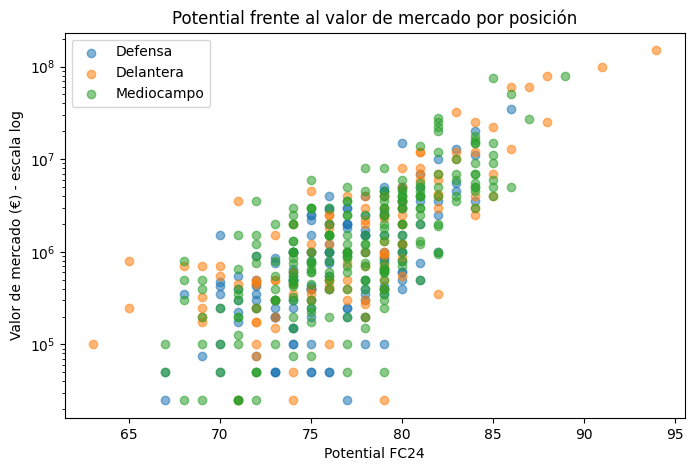

Candidatos exploratorios: 236


,long_name,nationality_name,club_name,posicion_agrupada,overall,potential,potential_gap,market_value_in_eur,mediana_valor_pares,ratio_valor_vs_pares,n_pares
371,Nicolás Paz,Argentina,Unión Santa Fe,Defensa,67,75,8,50000.0,650000.0,0.076923,70
463,Tomás Alejandro Castro,Argentina,Belgrano,Mediocampo,63,72,9,25000.0,300000.0,0.083333,56
488,Patricio Tanda,Argentina,Unión Santa Fe,Mediocampo,62,71,9,25000.0,300000.0,0.083333,56
328,Carlos Miguel Paraco González,Venezuela,Deportivo Táchira,Mediocampo,60,69,9,25000.0,300000.0,0.083333,56
405,Joaquín Panichelli,Argentina,Deportivo Alavés,Delantera,62,79,17,25000.0,287500.0,0.086957,24
323,Matías Hernández,Argentina,San Lorenzo,Delantera,60,74,14,25000.0,287500.0,0.086957,24
387,Manuel Brondo,Argentina,Barracas Central,Delantera,63,71,8,25000.0,287500.0,0.086957,24
389,Mateo Del Blanco,Argentina,Unión Santa Fe,Defensa,64,77,13,25000.0,275000.0,0.090909,38
301,Ronaldo De Jesús,Paraguay,Cerro Porteño,Defensa,60,67,7,25000.0,275000.0,0.090909,38
418,Gregorio Rodríguez,Argentina,Instituto,Mediocampo,65,70,5,100000.0,900000.0,0.111111,93


Cobertura Banco Mundial en la base valorizada: 100.0 %
Correlación exploratoria log(PBI pc) vs log(valor): 0.123
Interpretación: asociación descriptiva; no implica causalidad individual.


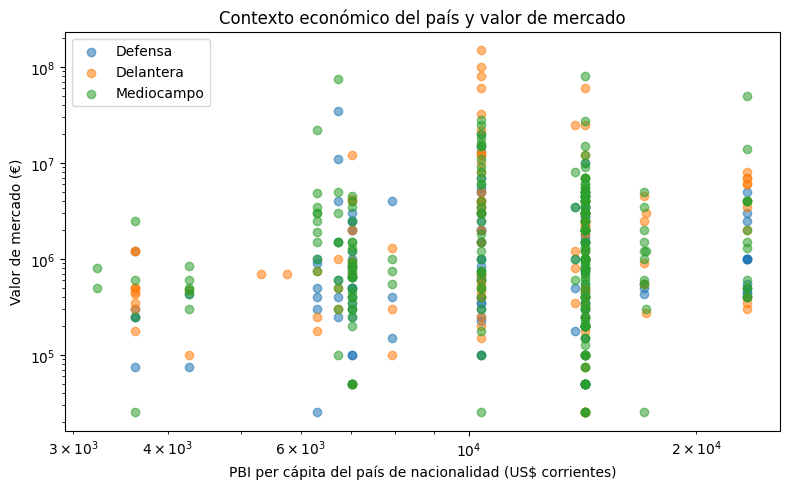

In [61]:
analisis_pc1 = dataset_valor_fc24[
    dataset_valor_fc24['market_value_in_eur'].notna()
    & (dataset_valor_fc24['market_value_in_eur'] > 0)
].copy()
analisis_pc1['potential_gap'] = analisis_pc1['potential'] - analisis_pc1['overall']

def agrupar_posicion(posiciones):
    pos = str(posiciones).split(',')[0].strip()
    if pos in ['CB', 'LB', 'RB', 'LWB', 'RWB']:
        return 'Defensa'
    if pos in ['CM', 'CDM', 'CAM', 'LM', 'RM']:
        return 'Mediocampo'
    if pos in ['ST', 'CF', 'RW', 'LW']:
        return 'Delantera'
    return 'Otra'

analisis_pc1['posicion_agrupada'] = analisis_pc1['player_positions'].apply(agrupar_posicion)
analisis_pc1['banda_overall'] = (analisis_pc1['overall'] // 5 * 5).astype(int)
benchmark = (
    analisis_pc1.groupby(['posicion_agrupada', 'banda_overall'])
    .agg(
        mediana_valor_pares=('market_value_in_eur', 'median'),
        n_pares=('player_id_fc24', 'count')
    )
    .reset_index()
)
analisis_pc1 = analisis_pc1.merge(
    benchmark,
    on=['posicion_agrupada', 'banda_overall'],
    how='left'
)
analisis_pc1['ratio_valor_vs_pares'] = (
    analisis_pc1['market_value_in_eur'] / analisis_pc1['mediana_valor_pares']
)

senales_exploratorias = analisis_pc1[
    (analisis_pc1['n_pares'] >= 5)
    & (analisis_pc1['ratio_valor_vs_pares'] < 1)
    & (analisis_pc1['potential_gap'] > 0)
].sort_values(['ratio_valor_vs_pares', 'potential'], ascending=[True, False])

plt.figure(figsize=(8, 5))
for posicion, grupo in analisis_pc1.groupby('posicion_agrupada'):
    plt.scatter(grupo['potential'], grupo['market_value_in_eur'], alpha=0.55, label=posicion)
plt.yscale('log')
plt.xlabel('Potential FC24')
plt.ylabel('Valor de mercado (€) - escala log')
plt.title('Potential frente al valor de mercado por posición')
plt.legend()
plt.show()

print('Candidatos exploratorios:', len(senales_exploratorias))
display(senales_exploratorias[[
    'long_name', 'nationality_name', 'club_name', 'posicion_agrupada',
    'overall', 'potential', 'potential_gap', 'market_value_in_eur',
    'mediana_valor_pares', 'ratio_valor_vs_pares', 'n_pares'
]].head(15))

contexto_bm = analisis_pc1[
    analisis_pc1['pib_per_capita_usd'].notna()
    & (analisis_pc1['pib_per_capita_usd'] > 0)
].copy()
contexto_bm['log_pib_pc'] = np.log10(contexto_bm['pib_per_capita_usd'])
contexto_bm['log_valor_mercado'] = np.log10(contexto_bm['market_value_in_eur'])
correlacion_bm_valor = contexto_bm[['log_pib_pc', 'log_valor_mercado']].corr().iloc[0, 1]

print('Cobertura Banco Mundial en la base valorizada:',
      round(100 * len(contexto_bm) / len(analisis_pc1), 2), '%')
print('Correlación exploratoria log(PBI pc) vs log(valor):',
      round(correlacion_bm_valor, 3))
print('Interpretación: asociación descriptiva; no implica causalidad individual.')

plt.figure(figsize=(8, 5))
for posicion, grupo in contexto_bm.groupby('posicion_agrupada'):
    plt.scatter(
        grupo['pib_per_capita_usd'],
        grupo['market_value_in_eur'],
        alpha=0.55,
        label=posicion
    )
plt.xscale('log')
plt.yscale('log')
plt.xlabel('PBI per cápita del país de nacionalidad (US$ corrientes)')
plt.ylabel('Valor de mercado (€)')
plt.title('Contexto económico del país y valor de mercado')
plt.legend()
plt.tight_layout()
plt.show()


## Integración de las 60 fichas jugador-partido

El archivo `Relevamiento_Liga1_U23.xlsm` contiene 60 filas de observación. El notebook usa minutos, intercepciones, pases totales y regates exitosos; agrega primero los conteos y minutos por jugador y después calcula tasas por 90.



Fuente: SofaScore (fuente pública secundaria)
Fichas recibidas: 60
Fichas válidas: 60
Partidos distintos: 52
Jugadores distintos: 8
Tasa de filas válidas: 100.0 %
Distribución por temporada:


,fichas
temporada_partido,
2023,48
2024,7
2026,5


Grupos jugador-temporada con titularidades contradictorias: 0
Tasa de cruce observaciones → FC24/Transfermarkt: 100.0 %
No cruzados: 0


,jugador,partidos_observados,minutos_observados,intercepciones_total,pases_totales,regates_exitosos_total,posicion_rel,titularidades_por_temporada,intercepciones_90,pases_totales_90,...,nationality_name,club_name,age,overall,potential,potential_gap,market_value_in_eur,ratio_valor_vs_pares,pib_per_capita_usd,anio_pib
7,Piero Aldair Quispe Córdova,8,455,7,187,10,CAM,2023: 28,1.384615,36.989011,...,Peru,Universitario,21,71,76,5,1000000.0,0.285714,7919.046348,2023
0,Anderson Mishael Villacorta Beltrán,7,454,12,201,1,CB,2023: 8,2.378855,39.845815,...,Peru,César Vallejo,17,62,74,12,150000.0,0.545455,7919.046348,2023
4,Juan Pablo Goicochea Del Carpio,6,378,2,108,5,ST,2023: 0 | 2026: 4,0.476190,25.714286,...,Peru,Alianza Lima,18,61,72,11,100000.0,0.347826,7919.046348,2023
1,Carlos Percy Liza Espinoza,7,270,0,61,5,ST,2024: 9,0.000000,20.333333,...,Peru,Sporting Cristal,23,66,73,7,300000.0,0.333333,7919.046348,2023
6,Matías Fernando Lazo Zapata,8,519,5,217,5,CB,2023: 9,0.867052,37.630058,...,Peru,Melgar,19,66,79,13,400000.0,0.615385,7919.046348,2023
5,Kenji Giovanni Cabrera Nakamura,8,266,3,87,4,CM,2023: 15,1.015038,29.436090,...,Peru,Melgar,20,66,76,10,550000.0,0.611111,7919.046348,2023
3,Joao Alberto Grimaldo Ubidia,8,591,5,133,7,RW,2023: 26,0.761421,20.253807,...,Peru,Sporting Cristal,20,69,79,10,1300000.0,1.444444,7919.046348,2023
2,Franco Zanelatto Téllez,8,365,3,72,5,RM,2023: 16,0.739726,17.753425,...,Paraguay,Alianza Lima,23,68,74,6,750000.0,0.833333,6303.264950,2023


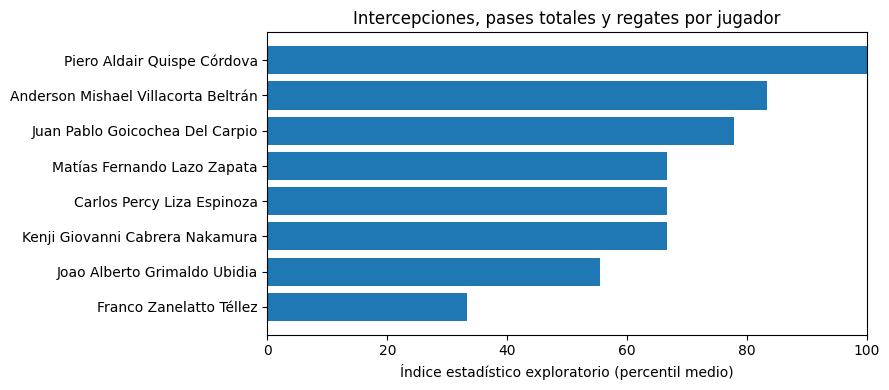

In [62]:
from pathlib import Path

ruta_relevamiento = Path('/content/Relevamiento_Liga1_U23.xlsm')

if not ruta_relevamiento.exists():
    print('PENDIENTE: subir Relevamiento_Liga1_U23.xlsm a /content.')
else:
    rel = pd.read_excel(
        ruta_relevamiento,
        sheet_name='Observaciones',
        header=3,
        engine='openpyxl'
    )

    rel.columns = [
        normalizar_nombre(columna).replace(' ', '_')
        for columna in rel.columns
    ]
    rel = rel.rename(columns={
        'id': 'id_obs',
        'club_de_referencia': 'club_rel',
        'edad_fc24': 'edad_rel',
        'posicion': 'posicion_rel',
        'titularidades_temporada_de_referencia_2023': 'titularidades_temporada',
        'temporada_del_partido': 'temporada_partido',
        'fecha_del_partido': 'fecha_partido',
        'minutos_jugados': 'minutos_jugados',
        'pases_totales': 'pases_totales',
        'regates_exitosos': 'regates_exitosos',
        'fuente_del_partido': 'fuente_partido',
        'fecha_y_hora_de_extraccion': 'fecha_hora_registro'
    })
    rel = rel[rel['jugador'].notna()].copy()

    requeridas = [
        'id_obs', 'jugador', 'posicion_rel', 'titularidades_temporada',
        'fuente_titularidades', 'temporada_partido', 'fecha_partido', 'rival',
        'minutos_jugados', 'intercepciones', 'pases_totales',
        'regates_exitosos', 'fuente_partido', 'fecha_hora_registro',
        'responsable', 'estado'
    ]
    faltantes = [columna for columna in requeridas if columna not in rel.columns]
    if faltantes:
        raise ValueError(f'Faltan columnas obligatorias: {faltantes}')

    rel['fecha_partido'] = pd.to_datetime(rel['fecha_partido'], errors='coerce')
    rel['fecha_hora_registro'] = pd.to_datetime(rel['fecha_hora_registro'], errors='coerce')
    numericas = [
        'titularidades_temporada', 'temporada_partido', 'minutos_jugados',
        'intercepciones', 'pases_totales', 'regates_exitosos'
    ]
    for columna in numericas:
        rel[columna] = pd.to_numeric(rel[columna], errors='coerce')

    rel['codigo_partido'] = (
        rel['fuente_partido'].astype(str).str.strip()
        + '|'
        + rel['fecha_partido'].dt.strftime('%Y-%m-%d').fillna('sin_fecha')
    )

    estado_norm = rel['estado'].astype(str).apply(normalizar_nombre)
    campos_completos = [columna for columna in requeridas if columna != 'estado']
    rel_validas = rel[
        estado_norm.eq('valida')
        & rel[campos_completos].notna().all(axis=1)
        & rel['minutos_jugados'].gt(0)
    ].copy()

    n_recibidas = len(rel)
    n_validas = len(rel_validas)
    n_partidos = rel_validas['codigo_partido'].nunique()
    n_jugadores = rel_validas['jugador'].nunique()
    print('Fuente: SofaScore (fuente pública secundaria)')
    print('Fichas recibidas:', n_recibidas)
    print('Fichas válidas:', n_validas)
    print('Partidos distintos:', n_partidos)
    print('Jugadores distintos:', n_jugadores)
    print('Tasa de filas válidas:', round(100 * n_validas / n_recibidas, 2), '%')
    print('Distribución por temporada:')
    display(rel_validas['temporada_partido'].value_counts().sort_index().rename('fichas'))

    inconsistencias_titularidad = (
        rel_validas.groupby(['jugador', 'temporada_partido'])['titularidades_temporada']
        .nunique(dropna=True)
        .loc[lambda serie: serie > 1]
    )
    print('Grupos jugador-temporada con titularidades contradictorias:',
          len(inconsistencias_titularidad))

    if n_validas:
        posiciones_jugador = (
            rel_validas.groupby('jugador')['posicion_rel']
            .first()
            .rename('posicion_rel')
            .reset_index()
        )
        titularidades_detalle = (
            rel_validas.groupby(['jugador', 'temporada_partido'])['titularidades_temporada']
            .first()
            .reset_index()
            .assign(detalle=lambda tabla: (
                tabla['temporada_partido'].astype('Int64').astype(str)
                + ': '
                + tabla['titularidades_temporada'].astype('Int64').astype(str)
            ))
            .groupby('jugador')['detalle']
            .agg(' | '.join)
            .rename('titularidades_por_temporada')
            .reset_index()
        )

        resumen_rel_jugador = (
            rel_validas.groupby('jugador')
            .agg(
                partidos_observados=('codigo_partido', 'nunique'),
                minutos_observados=('minutos_jugados', 'sum'),
                intercepciones_total=('intercepciones', 'sum'),
                pases_totales=('pases_totales', 'sum'),
                regates_exitosos_total=('regates_exitosos', 'sum')
            )
            .reset_index()
            .merge(posiciones_jugador, on='jugador', how='left', validate='one_to_one')
            .merge(titularidades_detalle, on='jugador', how='left', validate='one_to_one')
        )

        for origen, destino in {
            'intercepciones_total': 'intercepciones_90',
            'pases_totales': 'pases_totales_90',
            'regates_exitosos_total': 'regates_exitosos_90'
        }.items():
            resumen_rel_jugador[destino] = (
                resumen_rel_jugador[origen]
                / resumen_rel_jugador['minutos_observados']
                * 90
            )

        resumen_rel_jugador['posicion_agrupada_rel'] = (
            resumen_rel_jugador['posicion_rel'].apply(agrupar_posicion)
        )
        metricas_indice = [
            'intercepciones_90', 'pases_totales_90', 'regates_exitosos_90'
        ]
        for metrica in metricas_indice:
            resumen_rel_jugador[f'pct_{metrica}'] = (
                resumen_rel_jugador.groupby('posicion_agrupada_rel')[metrica]
                .rank(pct=True, method='average') * 100
            )
        resumen_rel_jugador['indice_publico_equilibrado'] = (
            resumen_rel_jugador[[f'pct_{metrica}' for metrica in metricas_indice]]
            .mean(axis=1)
        )

        resumen_rel_jugador['nombre_norm'] = (
            resumen_rel_jugador['jugador'].apply(normalizar_nombre)
        )
        base_cruce_rel = analisis_pc1.copy()
        base_cruce_rel['nombre_norm'] = base_cruce_rel['long_name'].apply(normalizar_nombre)
        rel_cruzado = resumen_rel_jugador.merge(
            base_cruce_rel[[
                'player_id_fc24', 'nombre_norm', 'long_name', 'nationality_name',
                'club_name', 'age', 'overall', 'potential', 'potential_gap',
                'market_value_in_eur', 'ratio_valor_vs_pares',
                'pib_per_capita_usd', 'anio_pib'
            ]].drop_duplicates('player_id_fc24'),
            on='nombre_norm',
            how='left',
            validate='one_to_one'
        )
        tasa_cruce_rel = 100 * rel_cruzado['player_id_fc24'].notna().mean()
        print('Tasa de cruce observaciones → FC24/Transfermarkt:',
              round(tasa_cruce_rel, 2), '%')
        print('No cruzados:', int(rel_cruzado['player_id_fc24'].isna().sum()))
        display(rel_cruzado.sort_values(
            ['indice_publico_equilibrado', 'ratio_valor_vs_pares'],
            ascending=[False, True]
        ))

        grafico = resumen_rel_jugador.sort_values('indice_publico_equilibrado')
        plt.figure(figsize=(9, max(4, 0.48 * len(grafico))))
        plt.barh(grafico['jugador'], grafico['indice_publico_equilibrado'])
        plt.xlabel('Índice estadístico exploratorio (percentil medio)')
        plt.title('Intercepciones, pases totales y regates por jugador')
        plt.xlim(0, 100)
        plt.tight_layout()
        plt.show()
    else:
        print('No existen filas válidas para ejecutar el análisis.')


In [63]:
df_obs = pd.read_excel(
    '/content/Relevamiento_Liga1_U23.xlsm',
    sheet_name='Observaciones',
    header=3,
    engine='openpyxl'
)

df_obs = df_obs[
    df_obs['Jugador'].notna()
    & df_obs['Estado'].eq('Válida')
    & df_obs['Minutos jugados'].gt(0)
].copy()

df_obs['codigo_partido'] = (
    df_obs['Fuente del partido'].astype(str).str.strip()
    + '|'
    + pd.to_datetime(
        df_obs['Fecha del partido'],
        errors='coerce'
    ).dt.strftime('%Y-%m-%d')
)

resumen_obs = (
    df_obs.groupby('Jugador', as_index=False)
    .agg(
        fichas_observadas=('ID', 'count'),
        partidos_observados=('codigo_partido', 'nunique'),
        minutos_observados=('Minutos jugados', 'sum'),
        pases_observados=('Pases totales', 'sum'),
        intercepciones_observadas=('Intercepciones', 'sum'),
        regates_observados=('Regates exitosos', 'sum')
    )
)

resumen_obs['nombre_norm'] = (
    resumen_obs['Jugador'].apply(normalizar_nombre)
)

resumen_obs['pases_por_90'] = (
    resumen_obs['pases_observados']
    / resumen_obs['minutos_observados']
    * 90
)

resumen_obs['intercepciones_por_90'] = (
    resumen_obs['intercepciones_observadas']
    / resumen_obs['minutos_observados']
    * 90
)

resumen_obs['regates_por_90'] = (
    resumen_obs['regates_observados']
    / resumen_obs['minutos_observados']
    * 90
)

cruce_relevamiento_fc24 = resumen_obs.merge(
    dataset_cruzado[
        [
            'player_id_fc24',
            'nombre_norm',
            'long_name',
            'club_name',
            'overall',
            'potential',
            'pib_per_capita_usd'
        ]
    ],
    on='nombre_norm',
    how='left',
    validate='one_to_one'
)

tasa_cruce_fc24 = (
    cruce_relevamiento_fc24['player_id_fc24'].notna().mean() * 100
)

print(
    'Tasa de cruce relevamiento → FC24/Transfermarkt:',
    round(tasa_cruce_fc24, 2),
    '%'
)

dataset_pc1_final = cruce_relevamiento_fc24.merge(
    analisis_pc1[
        [
            'player_id_fc24',
            'market_value_in_eur',
            'mediana_valor_pares',
            'ratio_valor_vs_pares',
            'potential_gap'
        ]
    ],
    on='player_id_fc24',
    how='left',
    validate='one_to_one'
)

tasa_valorizacion_comparable = (
    dataset_pc1_final['market_value_in_eur'].notna().mean() * 100
)

print(
    'Tasa de cruce con valorización comparable:',
    round(tasa_valorizacion_comparable, 2),
    '%'
)

print('Dataset maestro consolidado:')

display(
    dataset_pc1_final[
        [
            'long_name',
            'club_name',
            'overall',
            'potential',
            'market_value_in_eur',
            'ratio_valor_vs_pares',
            'minutos_observados',
            'partidos_observados',
            'pases_por_90',
            'intercepciones_por_90',
            'regates_por_90'
        ]
    ]
)

Tasa de cruce relevamiento → FC24/Transfermarkt: 100.0 %
Tasa de cruce con valorización comparable: 100.0 %
Dataset maestro consolidado:


,long_name,club_name,overall,potential,market_value_in_eur,ratio_valor_vs_pares,minutos_observados,partidos_observados,pases_por_90,intercepciones_por_90,regates_por_90
0,Anderson Mishael Villacorta Beltrán,César Vallejo,62,74,150000.0,0.545455,454,7,39.845815,2.378855,0.198238
1,Carlos Percy Liza Espinoza,Sporting Cristal,66,73,300000.0,0.333333,270,7,20.333333,0.000000,1.666667
2,Franco Zanelatto Téllez,Alianza Lima,68,74,750000.0,0.833333,365,8,17.753425,0.739726,1.232877
3,Joao Alberto Grimaldo Ubidia,Sporting Cristal,69,79,1300000.0,1.444444,591,8,20.253807,0.761421,1.065990
4,Juan Pablo Goicochea Del Carpio,Alianza Lima,61,72,100000.0,0.347826,378,6,25.714286,0.476190,1.190476
5,Kenji Giovanni Cabrera Nakamura,Melgar,66,76,550000.0,0.611111,266,8,29.436090,1.015038,1.353383
6,Matías Fernando Lazo Zapata,Melgar,66,79,400000.0,0.615385,519,8,37.630058,0.867052,0.867052
7,Piero Aldair Quispe Córdova,Universitario,71,76,1000000.0,0.285714,455,8,36.989011,1.384615,1.978022


## Validación del dataset integrado final

Se comprueba que el cruce entre el relevamiento, FC24 y Transfermarkt no haya generado jugadores duplicados, valores de mercado faltantes, minutos inválidos ni métricas incompletas.

In [64]:
print('Filas del dataset:', len(dataset_pc1_final))

print(
    'Jugadores únicos:',
    dataset_pc1_final['player_id_fc24'].nunique()
)

print(
    'Jugadores duplicados:',
    dataset_pc1_final['player_id_fc24'].duplicated().sum()
)

print(
    'Valores de mercado faltantes:',
    dataset_pc1_final['market_value_in_eur'].isna().sum()
)

print(
    'Valores de mercado no positivos:',
    (dataset_pc1_final['market_value_in_eur'] <= 0).sum()
)

print(
    'Minutos faltantes:',
    dataset_pc1_final['minutos_observados'].isna().sum()
)

print(
    'Minutos no positivos:',
    (dataset_pc1_final['minutos_observados'] <= 0).sum()
)

print(
    'Métricas por 90 minutos faltantes:',
    dataset_pc1_final[
        [
            'pases_por_90',
            'intercepciones_por_90',
            'regates_por_90'
        ]
    ].isna().sum().sum()
)

Filas del dataset: 8
Jugadores únicos: 8
Jugadores duplicados: 0
Valores de mercado faltantes: 0
Valores de mercado no positivos: 0
Minutos faltantes: 0
Minutos no positivos: 0
Métricas por 90 minutos faltantes: 0


## Exportación de los datasets limpios y enriquecidos

Se guardan las bases resultantes del proceso de limpieza, validación, cruce y enriquecimiento. Estos archivos serán utilizados posteriormente para la regresión supervisada, el análisis de series temporales, el clustering y la construcción del dashboard.

La exportación incluye el mapa definitivo de coincidencias entre FC24 y Transfermarkt, el historial de valorizaciones, la base con valores comparables dentro de la ventana seleccionada de 180 días, el contexto económico del Banco Mundial, el resumen del relevamiento y el dataset integrado final.

In [65]:
from pathlib import Path

carpeta_salida = Path('/content/drive/MyDrive/Caso_C_Grupo4')
carpeta_salida.mkdir(parents=True, exist_ok=True)

mapa_matches_definitivo.to_csv(
    carpeta_salida / 'mapa_matches_definitivo.csv', index=False, encoding='utf-8-sig'
)
dataset_historial.to_csv(
    carpeta_salida / 'dataset_fc24_transfermarkt_historial.csv', index=False, encoding='utf-8-sig'
)
dataset_valor_fc24.to_csv(
    carpeta_salida / 'dataset_valor_fc24.csv', index=False, encoding='utf-8-sig'
)
wb_pib.to_csv(
    carpeta_salida / 'contexto_banco_mundial_pib_per_capita.csv',
    index=False,
    encoding='utf-8-sig'
)
if 'senales_exploratorias' in globals():
    senales_exploratorias.to_csv(
        carpeta_salida / 'senales_exploratorias.csv', index=False, encoding='utf-8-sig'
    )
if 'resumen_rel_jugador' in globals():
    resumen_rel_jugador.to_csv(
        carpeta_salida / 'resumen_observaciones_jugador.csv', index=False, encoding='utf-8-sig'
    )
if 'dataset_pc1_final' in globals():
    dataset_pc1_final.to_csv(
        carpeta_salida / 'resultado_integrado_final.csv',
        index=False,
        encoding='utf-8-sig'
    )

print('Archivos finales guardados en:', carpeta_salida)


Archivos finales guardados en: /content/drive/MyDrive/Caso_C_Grupo4


## Verificación de los archivos exportados

Se vuelven a leer los archivos guardados para comprobar que fueron generados correctamente y que corresponden a las versiones actualizadas de las bases.

In [66]:
archivos_exportados = [
    'mapa_matches_definitivo.csv',
    'dataset_fc24_transfermarkt_historial.csv',
    'dataset_valor_fc24.csv',
    'contexto_banco_mundial_pib_per_capita.csv',
    'senales_exploratorias.csv',
    'resumen_observaciones_jugador.csv',
    'resultado_integrado_final.csv'
]

for archivo in archivos_exportados:
    ruta_archivo = carpeta_salida / archivo

    if ruta_archivo.exists():
        datos_guardados = pd.read_csv(ruta_archivo)

        print(
            archivo,
            '→',
            len(datos_guardados),
            'filas y',
            len(datos_guardados.columns),
            'columnas'
        )
    else:
        print(archivo, '→ NO ENCONTRADO')

mapa_matches_definitivo.csv → 580 filas y 4 columnas
dataset_fc24_transfermarkt_historial.csv → 6949 filas y 124 columnas
dataset_valor_fc24.csv → 498 filas y 125 columnas
contexto_banco_mundial_pib_per_capita.csv → 18 filas y 4 columnas
senales_exploratorias.csv → 236 filas y 130 columnas
resumen_observaciones_jugador.csv → 8 filas y 17 columnas
resultado_integrado_final.csv → 8 filas y 21 columnas


## Control de calidad de los datasets exportados

Se verifica la unicidad de los identificadores, la ausencia de valorizaciones faltantes o futuras y el cumplimiento de la ventana temporal de 180 días.

In [67]:
mapa_exportado = pd.read_csv(
    carpeta_salida / 'mapa_matches_definitivo.csv'
)

valores_exportados = pd.read_csv(
    carpeta_salida / 'dataset_valor_fc24.csv'
)

integrado_exportado = pd.read_csv(
    carpeta_salida / 'resultado_integrado_final.csv'
)

print(
    'IDs FC24 duplicados en el mapa:',
    mapa_exportado['player_id_fc24'].duplicated().sum()
)

print(
    'IDs Transfermarkt duplicados en el mapa:',
    mapa_exportado['player_id_tm'].duplicated().sum()
)

print(
    'Jugadores únicos en la base valorizada:',
    valores_exportados['player_id_fc24'].nunique()
)

print(
    'Jugadores duplicados en la base valorizada:',
    valores_exportados['player_id_fc24'].duplicated().sum()
)

print(
    'Valores de mercado faltantes:',
    valores_exportados['market_value_in_eur'].isna().sum()
)

print(
    'Mayor antigüedad de la valorización:',
    valores_exportados['dias_antes_fc24'].max(),
    'días'
)

print(
    'Jugadores duplicados en el resultado integrado:',
    integrado_exportado['player_id_fc24'].duplicated().sum()
)

IDs FC24 duplicados en el mapa: 0
IDs Transfermarkt duplicados en el mapa: 0
Jugadores únicos en la base valorizada: 498
Jugadores duplicados en la base valorizada: 0
Valores de mercado faltantes: 0
Mayor antigüedad de la valorización: 172 días
Jugadores duplicados en el resultado integrado: 0


## Inventario de datasets originales y procesados

Se documentan los archivos utilizados y generados durante el proyecto. Los datasets originales se conservan sin modificaciones, mientras que los archivos procesados contienen los resultados de la limpieza, validación, integración y enriquecimiento.

In [68]:
inventario_datasets = pd.DataFrame([
    {
        'archivo': 'male_players.csv',
        'tipo': 'Original',
        'contenido': 'Atributos deportivos de jugadores de FC24'
    },
    {
        'archivo': 'players.csv',
        'tipo': 'Original',
        'contenido': 'Identificación y características de jugadores de Transfermarkt'
    },
    {
        'archivo': 'player_valuations.csv',
        'tipo': 'Original',
        'contenido': 'Historial de valorizaciones de Transfermarkt'
    },
    {
        'archivo': 'Relevamiento_Liga1_U23.xlsm',
        'tipo': 'Original',
        'contenido': '60 fichas jugador-partido de ocho jugadores de Liga 1 U23'
    },
    {
        'archivo': 'mapa_matches_definitivo.csv',
        'tipo': 'Procesado',
        'contenido': 'Correspondencias validadas entre FC24 y Transfermarkt'
    },
    {
        'archivo': 'dataset_fc24_transfermarkt_historial.csv',
        'tipo': 'Procesado',
        'contenido': 'Atributos deportivos e historial de valorizaciones'
    },
    {
        'archivo': 'dataset_valor_fc24.csv',
        'tipo': 'Procesado',
        'contenido': '498 jugadores con valorización comparable dentro de 180 días'
    },
    {
        'archivo': 'contexto_banco_mundial_pib_per_capita.csv',
        'tipo': 'Procesado',
        'contenido': 'PBI per cápita utilizado como contexto económico'
    },
    {
        'archivo': 'senales_exploratorias.csv',
        'tipo': 'Resultado analítico',
        'contenido': '236 señales exploratorias de posible subvaloración'
    },
    {
        'archivo': 'resumen_observaciones_jugador.csv',
        'tipo': 'Procesado',
        'contenido': 'Resumen por jugador y métricas por 90 minutos'
    },
    {
        'archivo': 'resultado_integrado_final.csv',
        'tipo': 'Procesado',
        'contenido': 'Integración final del relevamiento, FC24 y Transfermarkt'
    }
])

display(inventario_datasets)

inventario_datasets.to_csv(
    carpeta_salida / 'inventario_datasets.csv',
    index=False,
    encoding='utf-8-sig'
)

print('Inventario guardado correctamente.')

,archivo,tipo,contenido
0,male_players.csv,Original,Atributos deportivos de jugadores de FC24
1,players.csv,Original,Identificación y características de jugadores ...
2,player_valuations.csv,Original,Historial de valorizaciones de Transfermarkt
3,Relevamiento_Liga1_U23.xlsm,Original,60 fichas jugador-partido de ocho jugadores de...
4,mapa_matches_definitivo.csv,Procesado,Correspondencias validadas entre FC24 y Transf...
5,dataset_fc24_transfermarkt_historial.csv,Procesado,Atributos deportivos e historial de valorizaci...
6,dataset_valor_fc24.csv,Procesado,498 jugadores con valorización comparable dent...
7,contexto_banco_mundial_pib_per_capita.csv,Procesado,PBI per cápita utilizado como contexto económico
8,senales_exploratorias.csv,Resultado analítico,236 señales exploratorias de posible subvalora...
9,resumen_observaciones_jugador.csv,Procesado,Resumen por jugador y métricas por 90 minutos


Inventario guardado correctamente.


## Conclusión preliminar actualizada

Como continuación de la presentación anterior de la PC1, se revisaron y actualizaron algunos componentes metodológicos del análisis, principalmente la ventana utilizada para seleccionar las valorizaciones de Transfermarkt. El objetivo del proyecto se mantiene: evaluar la viabilidad de una propuesta analítica para identificar posibles jugadores latinoamericanos U23 subvalorados mediante la integración de atributos deportivos, valorizaciones históricas, contexto económico y estadísticas complementarias de rendimiento.

El EDA confirmó diferencias relevantes en edad, posición, nivel actual, potencial y valor de mercado. Asimismo, mostró que las valorizaciones tienen una distribución fuertemente asimétrica: existe una alta concentración de jugadores con valores bajos y medios y una menor cantidad de jugadores con valores muy elevados. Esta característica justifica el uso de una transformación logarítmica del valor de mercado en la etapa posterior de regresión.

El proceso de limpieza, normalización y validación permitió vincular 580 de los 1,070 jugadores de FC24 con Transfermarkt, alcanzando una tasa de coincidencia de 54.21%. Para evitar asociaciones dudosas, se combinaron coincidencias exactas y fuzzy matching restringido por fecha de nacimiento, manteniendo únicamente pares con evidencia suficiente.

En la presentación anterior se utilizó una ventana temporal de 90 días, que proporcionó una valorización comparable para 377 jugadores. En esta actualización se compararon ventanas de 90, 180 y 365 días. Se seleccionó la ventana de 180 días porque elevó la cobertura a 498 jugadores, equivalente al 85.86% de los jugadores cruzados, mientras que la ventana de 365 días solo incorporaba tres jugadores adicionales y permitía utilizar información considerablemente más antigua. La mayor antigüedad dentro de la ventana seleccionada fue de 172 días y no se utilizaron valorizaciones posteriores a la fecha de referencia de FC24.

La ampliación de la base también actualizó el análisis exploratorio de subvaloración. Las señales identificadas aumentaron de 174 a 236 jugadores que presentan un valor inferior a la mediana de pares con posición y nivel similares, además de una brecha positiva entre potencial y overall. Estas señales representan candidatos para análisis posterior y no deben interpretarse todavía como recomendaciones definitivas de inversión.

El Banco Mundial aportó el PBI per cápita como una variable de contexto económico del país de nacionalidad. Su relación con el valor de mercado es descriptiva y no demuestra que el nivel económico de un país cause directamente la valorización de un jugador. Por ello, esta información se utiliza como enriquecimiento contextual y no como criterio único de selección.

El relevamiento de 60 fichas jugador-partido incorporó estadísticas de pases, intercepciones y regates para ocho jugadores de la Liga 1 U23. En la presentación anterior, solo tres tenían una valorización comparable dentro de la ventana de 90 días. Con la actualización a 180 días, los ocho jugadores fueron vinculados con FC24 y Transfermarkt y cuentan con una valorización comparable. Esto permite ampliar el análisis de la pregunta huérfana, aunque sus resultados siguen siendo exploratorios debido al número reducido de jugadores observados.

Finalmente, los controles de calidad confirmaron que las bases exportadas no presentan identificadores duplicados, valores de mercado faltantes ni registros fuera de la ventana seleccionada. En consecuencia, se dispone de una base limpia, validada y enriquecida para continuar. Estas etapas permitirán convertir las señales exploratorias actuales en una priorización de jugadores más sólida y accionable.

## Plan de trabajo para la fase 2


| Semana | Objetivo | Actividades | Entregable |
|---|---|---|---|
| 7 | Definir la base para el modelado | Comparar las ventanas de valorización de 90, 180 y 365 días. Evaluar la cobertura y antigüedad de los valores en cada ventana, seleccionar una con un criterio documentado y preparar las variables que ingresarán al modelo. | Base de modelado definitiva, comparación de ventanas y diccionario de variables. |
| 8 | Construir el modelo supervisado | Modelar el logaritmo del valor de mercado utilizando edad, posición, overall, potential y atributos deportivos. Separar los datos en entrenamiento y prueba. Comparar una regresión lineal o Ridge con un modelo de árboles sencillo, evitando variables que filtren información del valor observado. | Modelos iniciales y comparación mediante R², RMSE y MAE. |
| 9 | Identificar posibles jugadores subvalorados | Elegir el modelo con mejor desempeño razonable, calcular la diferencia entre el valor predicho y el observado, elaborar un ranking preliminar y revisar manualmente los casos extremos, las fechas de valorización y la calidad del matching. | Ranking preliminar de candidatos y explicación de los factores asociados al valor. |
| 10 | Analizar la evolución temporal | Transformar el historial de Transfermarkt en series mensuales. Calcular la mediana del valor de mercado por posición, exigir un mínimo de observaciones por mes y analizar tendencias, variaciones y posibles cambios estructurales sin completar artificialmente los periodos vacíos. | Series mensuales por posición y análisis descriptivo de tendencias. |
| 11 | Elaborar un pronóstico sencillo | Seleccionar las series que tengan suficiente historial. Comparar un pronóstico base, como el último valor o promedio móvil, con un modelo sencillo de suavizamiento exponencial. Aplicar una separación temporal y evaluar un horizonte corto. Las series sin datos suficientes serán declaradas no modelables. | Forecast por posición con MAE o RMSE y comparación contra el modelo base. |
| 12 | Construir arquetipos de jugadores | Seleccionar atributos deportivos, tratar valores faltantes y estandarizar las variables. Probar entre 3 y 6 clusters mediante K-means. Comparar el método del codo y el coeficiente silhouette. Describir los grupos según sus características deportivas, sin utilizar el valor de mercado para formar los clusters. | Arquetipos de jugadores, perfiles de cada cluster y oportunidades por segmento. |
| 13 | Integrar los resultados en Power BI | Preparar las tablas finales de regresión, ranking, series temporales, clusters y relevamiento. Construir entre 3 y 4 páginas del dashboard. Incorporar las observaciones de SofaScore como validación exploratoria e informar la cobertura obtenida con la ventana seleccionada. | Dashboard funcional y lista priorizada de jugadores. |
| 14 | Validar y comunicar las recomendaciones | Realizar un análisis de sensibilidad cambiando la ventana temporal, el umbral de subvaloración o el número de clusters. Comprobar que cada recomendación esté respaldada por un resultado, ejecutar el notebook completo y preparar la sustentación. | Presentación ejecutiva, informe final, notebook reproducible, dashboard y bitácora de IA actualizada. |

## Preparación de la base para el modelo supervisado

Para evitar repetir el procesamiento realizado en PC1, se utiliza `analisis_pc1`, que ya contiene los jugadores con valorizaciones válidas, posiciones agrupadas y atributos deportivos de FC24.

Se agrega únicamente el logaritmo del valor de mercado. Esta transformación facilita el modelamiento porque las valorizaciones presentan una distribución asimétrica y diferencias muy grandes entre jugadores.

In [69]:
base_modelo = analisis_pc1.copy()

base_modelo['log_valor_mercado'] = np.log10(
    base_modelo['market_value_in_eur']
)

variables_modelo = [
    'age',
    'overall',
    'potential',
    'pace',
    'shooting',
    'passing',
    'dribbling',
    'defending',
    'physic',
    'posicion_agrupada',
    'log_valor_mercado'
]

print('Jugadores disponibles para el modelo:', len(base_modelo))

print('\nValores faltantes por variable:')
display(
    base_modelo[variables_modelo]
    .isna()
    .sum()
    .to_frame('valores_faltantes')
)

display(
    base_modelo[
        [
            'long_name',
            'age',
            'posicion_agrupada',
            'overall',
            'potential',
            'market_value_in_eur',
            'log_valor_mercado'
        ]
    ].head(10)
)

Jugadores disponibles para el modelo: 498

Valores faltantes por variable:


,valores_faltantes
age,0
overall,0
potential,0
pace,0
shooting,0
passing,0
dribbling,0
defending,0
physic,0
posicion_agrupada,0


,long_name,age,posicion_agrupada,overall,potential,market_value_in_eur,log_valor_mercado
0,Anderson Arroyo Córdoba,23,Defensa,69,80,800000.0,5.903090
1,Erick Daniel Sánchez Ocegueda,23,Mediocampo,75,79,8000000.0,6.903090
2,Jaminton Leandro Campaz,23,Mediocampo,74,81,4000000.0,6.602060
3,Javier Adolfo Altamirano Altamirano,23,Mediocampo,71,74,2000000.0,6.301030
4,Vinícius José Paixão de Oliveira Júnior,22,Delantera,89,94,150000000.0,8.176091
5,Nicolás Esteban Fernández Muñoz,23,Defensa,64,71,550000.0,5.740363
6,Jader Andrés Valencia Mena,23,Mediocampo,67,74,450000.0,5.653213
7,Edgar Joel Elizalde Ferreira,23,Defensa,69,75,400000.0,5.602060
8,Braian Alejandro Galván,22,Mediocampo,64,72,1200000.0,6.079181
9,Facundo Tomás Garcés,23,Defensa,73,79,4500000.0,6.653213


## Regresión supervisada

Se continúa la preparación anterior con la misma base de 180 días y el mismo objetivo
en log10. Se comparan Ridge y Random Forest con la mediana como referencia, se reportan
métricas sobre prueba y se interpretan los resultados.

### 1. Predictores, controles y separación de la muestra

La separación por jugador es 80/20, con proporciones de macroposición preservadas y
semilla 42. Los identificadores y las variables derivadas del valor observado quedan
fuera de los predictores. En esta base corresponden 398 jugadores a entrenamiento y
100 a prueba.

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

if 'analisis_pc1' not in globals():
    raise RuntimeError('Ejecuta primero la celda que crea analisis_pc1.')

numericas = ['age', 'overall', 'potential', 'pace', 'shooting',
             'passing', 'dribbling', 'defending', 'physic']
categoricas = ['posicion_agrupada']
variables = numericas + categoricas
base_modelo = analisis_pc1.copy().reset_index(drop=True)
base_modelo['market_value_in_eur'] = pd.to_numeric(
    base_modelo['market_value_in_eur'], errors='coerce')
base_modelo = base_modelo[
    base_modelo['market_value_in_eur'].gt(0)
    & np.isfinite(base_modelo['market_value_in_eur'])
].copy().reset_index(drop=True)
if base_modelo['player_id_fc24'].isna().any() or not base_modelo['player_id_fc24'].is_unique:
    raise ValueError('La base debe tener un identificador único por jugador.')
base_modelo[numericas] = base_modelo[numericas].apply(
    pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)

X = base_modelo[variables]
base_modelo['log_valor_mercado'] = np.log10(base_modelo['market_value_in_eur'])
y_log = base_modelo['log_valor_mercado']
X_train, X_test, y_train, y_test = train_test_split(
    X, y_log, test_size=0.20, random_state=42,
    stratify=base_modelo['posicion_agrupada'])
print(f'Jugadores: {len(X)} | Entrenamiento: {len(X_train)} | Prueba: {len(X_test)}')


if 'carpeta_salida' in globals():
    carpeta_regresion = Path(carpeta_salida) / 'regresion_supervisada'
elif Path('/content/drive/MyDrive').exists():
    carpeta_regresion = Path('/content/drive/MyDrive/Caso_C_Grupo4/regresion_supervisada')
elif Path('/content').exists():
    carpeta_regresion = Path('/content/Caso_C_Grupo4/regresion_supervisada')
else:
    carpeta_regresion = Path.cwd() / 'resultados_regresion'
carpeta_regresion.mkdir(parents=True, exist_ok=True)
assert set(X_train.index).isdisjoint(X_test.index)
assert 'log_valor_mercado' not in X.columns
print('Objetivo: log10(valor de mercado en euros). Ventana de origen: 180 días.')


Jugadores: 498 | Entrenamiento: 398 | Prueba: 100
Objetivo: log10(valor de mercado en euros). Ventana de origen: 180 días.


### 2. Entrenamiento, validación cruzada y métricas

La elección utiliza el menor **RMSE log10 de validación cruzada de cinco particiones**
del entrenamiento. La imputación y el escalado están dentro de cada pipeline.
La muestra de prueba queda reservada para la evaluación.

| Métrica | Interpretación |
|---|---|
| `RMSE_log10_CV` | Promedio del RMSE log10 entre particiones de entrenamiento; menor es mejor. |
| `SD_RMSE_log10_CV` | Desviación entre particiones; no es un intervalo de confianza. |
| `R2_log10_prueba` | Ajuste en la escala log10 del objetivo. |
| `R2_eur_prueba` | Ajuste después de convertir las predicciones a euros. |
| `MAE_eur_prueba` | Error absoluto promedio, en euros por jugador de prueba. |
| `RMSE_eur_prueba` | Error en euros que penaliza más las desviaciones grandes. |

Un R² negativo indica peor desempeño que predecir la media de esa muestra de prueba.

In [71]:
preprocesador = ColumnTransformer([
    ('num', Pipeline([
        ('imputar', SimpleImputer(strategy='median')),
        ('escalar', StandardScaler())
    ]), numericas),
    ('cat', Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('codificar', OneHotEncoder(handle_unknown='ignore'))
    ]), categoricas)
])
algoritmos = {
    'Base_mediana': DummyRegressor(strategy='median'),
    'Ridge': Ridge(alpha=10.0),
    'RandomForest': RandomForestRegressor(
        n_estimators=200, max_depth=8, min_samples_leaf=3,
        random_state=42, n_jobs=-1)
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
modelos = {}
filas_cv = []
for nombre, algoritmo in algoritmos.items():
    modelos[nombre] = Pipeline([
        ('preparar', clone(preprocesador)), ('modelo', algoritmo)])
    mse_cv = -cross_val_score(
        modelos[nombre], X_train, y_train, cv=cv,
        scoring='neg_mean_squared_error', n_jobs=1)
    filas_cv.append({'modelo': nombre,
                     'RMSE_log10_CV': np.sqrt(mse_cv).mean(),
                     'SD_RMSE_log10_CV': np.sqrt(mse_cv).std(ddof=1)})

metricas_regresion = pd.DataFrame(filas_cv).set_index('modelo')
nombre_mejor = metricas_regresion['RMSE_log10_CV'].idxmin()
y_real = base_modelo.loc[X_test.index, 'market_value_in_eur']
predicciones_log = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    predicciones_log[nombre] = modelo.predict(X_test)
    pred_eur = np.maximum(np.power(10.0, predicciones_log[nombre]), 0)
    metricas_regresion.loc[nombre, 'R2_log10_prueba'] = r2_score(
        y_test, predicciones_log[nombre])
    metricas_regresion.loc[nombre, 'R2_eur_prueba'] = r2_score(y_real, pred_eur)
    metricas_regresion.loc[nombre, 'MAE_eur_prueba'] = mean_absolute_error(y_real, pred_eur)
    metricas_regresion.loc[nombre, 'RMSE_eur_prueba'] = np.sqrt(
        mean_squared_error(y_real, pred_eur))

metricas_regresion = metricas_regresion.sort_values('RMSE_log10_CV')
modelo_elegido = modelos[nombre_mejor]
y_pred_log = predicciones_log[nombre_mejor]
y_pred_eur = np.maximum(np.power(10.0, y_pred_log), 0)
print('Modelo elegido por validación cruzada:', nombre_mejor)
display(metricas_regresion.round(3))


Modelo elegido por validación cruzada: Ridge


,RMSE_log10_CV,SD_RMSE_log10_CV,R2_log10_prueba,R2_eur_prueba,MAE_eur_prueba,RMSE_eur_prueba
modelo,,,,,,
Ridge,0.421,0.070,0.710,0.763,2408756.362,9.139027e+06
RandomForest,0.422,0.052,0.700,0.669,2586932.256,1.079212e+07
Base_mediana,0.678,0.044,-0.001,-0.055,5064250.000,1.926029e+07


**Interpretación:** Ridge fue seleccionado porque obtuvo el menor RMSE promedio en la validación cruzada, con 0.421 frente a 0.422 de Random Forest. La diferencia es pequeña, pero Ridge ofrece un desempeño ligeramente mejor y una solución más sencilla.

En la muestra de prueba, Ridge alcanzó un R² de 0.710 en escala logarítmica y 0.763 en euros. Esto indica que explica aproximadamente 76.3% de la variación del valor de mercado en esa muestra. Su error absoluto promedio fue de aproximadamente €2.41 millones por jugador, mientras que el RMSE de €9.14 millones muestra que todavía existen errores grandes en jugadores de valor elevado.

La referencia basada en la mediana obtuvo un R² negativo, por lo que Ridge y Random Forest aportan una mejora real frente a una predicción básica. El modelo debe utilizarse como señal de priorización y no como una tasación exacta.

### 3. Predicciones, residuos e importancia de variables

La diagonal roja representa predicción perfecta. Los residuos se representan en log10.
La importancia por permutación mide el aumento del MAE log10 cuando se desordena cada
atributo en la prueba. Las importancias describen el uso de las variables por el modelo;
los atributos correlacionados pueden compartir importancia.

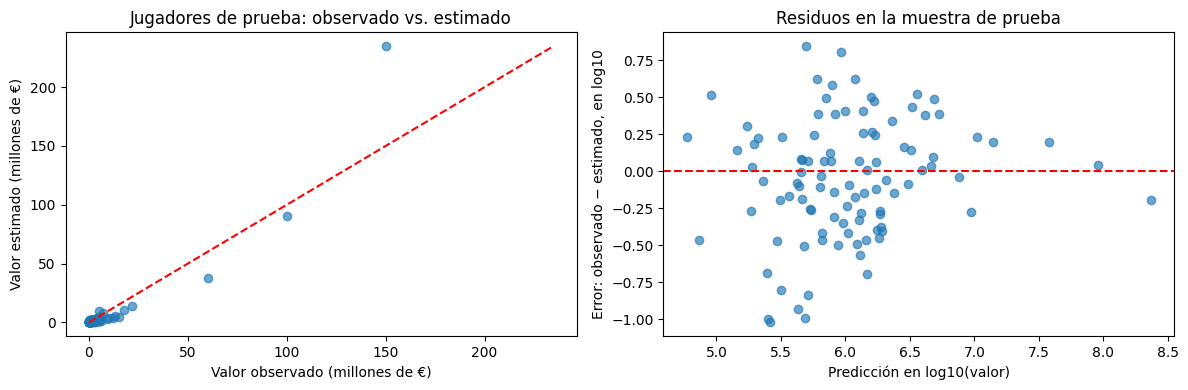

,variable,aumento_MAE_log10,desviacion
2,potential,0.1568,0.0195
1,overall,0.1330,0.0144
3,pace,0.0121,0.0040
9,posicion_agrupada,0.0087,0.0067
5,passing,0.0051,0.0021
7,defending,0.0048,0.0032
6,dribbling,0.0041,0.0016
8,physic,0.0036,0.0031
0,age,0.0036,0.0025
4,shooting,0.0000,0.0008


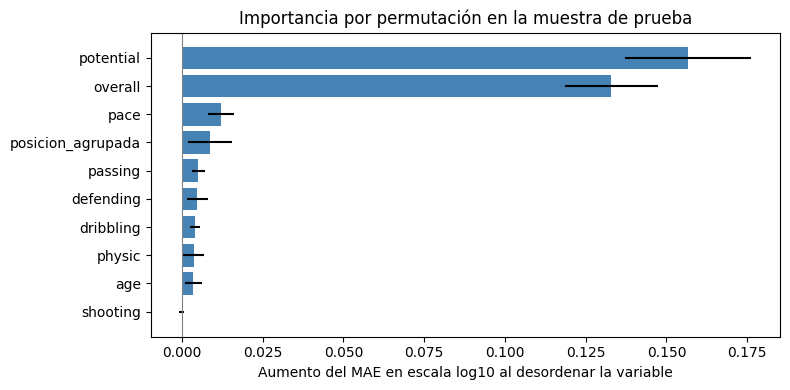

Modelo: Ridge. R² en euros (prueba): 0.763.
Error absoluto medio: €2,408,756 por jugador de prueba.
RMSE: €9,139,027; penaliza más los errores grandes.
Importancia positiva: desordenar la variable empeora la predicción.
Las importancias no indican causalidad ni el sentido del efecto;
los atributos correlacionados pueden compartir su importancia.
Se estima una valoración comparable a FC24; no se pronostica un ROI futuro.
La conversión desde log10 da una estimación central, no una media esperada corregida.
La cobertura y los posibles errores de matching limitan la generalización.


In [72]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(y_real / 1e6, y_pred_eur / 1e6, alpha=0.65)
limites = [0, max(y_real.max(), y_pred_eur.max()) / 1e6]
ax[0].plot(limites, limites, '--', color='red')
ax[0].set(xlabel='Valor observado (millones de €)',
          ylabel='Valor estimado (millones de €)',
          title='Jugadores de prueba: observado vs. estimado')
ax[1].scatter(y_pred_log, y_test - y_pred_log, alpha=0.65)
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set(xlabel='Predicción en log10(valor)',
          ylabel='Error: observado − estimado, en log10',
          title='Residuos en la muestra de prueba')
plt.tight_layout()
fig.savefig(carpeta_regresion / 'predicciones_y_residuos.png', dpi=160, bbox_inches='tight')
plt.show()

resultado_importancia = permutation_importance(
    modelo_elegido, X_test, y_test, scoring='neg_mean_absolute_error',
    n_repeats=10, random_state=42, n_jobs=1)
importancia_regresion = pd.DataFrame({
    'variable': variables,
    'aumento_MAE_log10': resultado_importancia.importances_mean,
    'desviacion': resultado_importancia.importances_std
}).sort_values('aumento_MAE_log10', ascending=False)
display(importancia_regresion.round(4))
grafico = importancia_regresion.sort_values('aumento_MAE_log10')
plt.figure(figsize=(8, 4))
plt.barh(grafico['variable'], grafico['aumento_MAE_log10'],
         xerr=grafico['desviacion'], color='steelblue')
plt.axvline(0, color='gray', linewidth=0.8)
plt.xlabel('Aumento del MAE en escala log10 al desordenar la variable')
plt.title('Importancia por permutación en la muestra de prueba')
plt.tight_layout()
plt.savefig(carpeta_regresion / 'importancia_variables.png', dpi=160, bbox_inches='tight')
plt.show()

m = metricas_regresion.loc[nombre_mejor]
print(f'Modelo: {nombre_mejor}. R² en euros (prueba): {m["R2_eur_prueba"]:.3f}.')
print(f'Error absoluto medio: €{m["MAE_eur_prueba"]:,.0f} por jugador de prueba.')
print(f'RMSE: €{m["RMSE_eur_prueba"]:,.0f}; penaliza más los errores grandes.')
if nombre_mejor == 'Base_mediana':
    print('Los modelos no mejoraron la base en CV: no hay evidencia para priorizarlos.')
if m['R2_eur_prueba'] < 0:
    print('R² negativo: el modelo rinde peor que predecir la media de la prueba.')
print('Importancia positiva: desordenar la variable empeora la predicción.')
print('Las importancias no indican causalidad ni el sentido del efecto;')
print('los atributos correlacionados pueden compartir su importancia.')
print('Se estima una valoración comparable a FC24; no se pronostica un ROI futuro.')
print('La conversión desde log10 da una estimación central, no una media esperada corregida.')
print('La cobertura y los posibles errores de matching limitan la generalización.')


### 4. Exportación de resultados tabulares

Se exportan la comparación de métricas, las predicciones y errores de los 100 jugadores
de prueba y la importancia de atributos. Una brecha estimada positiva es una señal
exploratoria para revisar; su interpretación depende también del error del modelo.

In [73]:
predicciones_regresion = base_modelo.loc[X_test.index, [
    'player_id_fc24', 'long_name', 'posicion_agrupada', 'market_value_in_eur'
]].copy()
predicciones_regresion['valor_estimado_eur'] = y_pred_eur
predicciones_regresion['error_absoluto_eur'] = np.abs(y_real - y_pred_eur)
predicciones_regresion['brecha_estimada_eur'] = y_pred_eur - y_real
predicciones_regresion['modelo'] = nombre_mejor
predicciones_regresion['conjunto'] = 'prueba'

metricas_regresion.to_csv(carpeta_regresion / 'metricas_regresion.csv', encoding='utf-8-sig')
predicciones_regresion.to_csv(carpeta_regresion / 'predicciones_regresion_prueba.csv',
                              index=False, encoding='utf-8-sig')
importancia_regresion.to_csv(carpeta_regresion / 'importancia_regresion.csv',
                            index=False, encoding='utf-8-sig')
print(f'Predicciones exportadas: {len(predicciones_regresion)} jugadores de prueba.')
display(predicciones_regresion.head(10).round(2))


Predicciones exportadas: 100 jugadores de prueba.


,player_id_fc24,long_name,posicion_agrupada,market_value_in_eur,valor_estimado_eur,error_absoluto_eur,brecha_estimada_eur,modelo,conjunto
367,271741,Patrik Kleiver Mercado Altamirano,Mediocampo,600000.0,1029699.19,429699.19,429699.19,Ridge,prueba
396,273463,João Victor Gomes da Silva,Mediocampo,18000000.0,10513266.28,7486733.72,-7486733.72,Ridge,prueba
256,264549,Kevin Andrés Mantilla Camargo,Defensa,2500000.0,984388.04,1515611.96,-1515611.96,Ridge,prueba
183,259874,César Nahuel Araújo Vilches,Mediocampo,2000000.0,1736896.94,263103.06,-263103.06,Ridge,prueba
107,255453,Juan Manuel Cruz,Delantera,450000.0,455786.59,5786.59,5786.59,Ridge,prueba
108,255475,Antony Matheus dos Santos,Delantera,60000000.0,37950107.46,22049892.54,-22049892.54,Ridge,prueba
493,278016,Murillo Costa dos Santos,Defensa,3500000.0,1370438.23,2129561.77,-2129561.77,Ridge,prueba
257,264570,José Alfredo Flores López,Mediocampo,300000.0,91479.22,208520.78,-208520.78,Ridge,prueba
5,239682,Nicolás Esteban Fernández Muñoz,Defensa,550000.0,320764.09,229235.91,-229235.91,Ridge,prueba
304,268484,Brian Mansilla,Mediocampo,500000.0,636082.06,136082.06,136082.06,Ridge,prueba


### 5. Interpretación y conclusión del modelo

La siguiente celda genera una interpretación con los valores calculados y la guarda
en `interpretacion_regresion.md`. Al volver a ejecutar el modelo se actualiza el texto.

In [74]:
from IPython.display import Markdown

seleccion = metricas_regresion.loc[nombre_mejor]
filas_metricas = [
    '| Modelo | RMSE log10 CV | R² log10 prueba | R² euros prueba | MAE euros | RMSE euros |',
    '|---|---:|---:|---:|---:|---:|',
]
for nombre, fila in metricas_regresion.iterrows():
    filas_metricas.append(
        f'| {nombre} | {fila["RMSE_log10_CV"]:.4f} | {fila["R2_log10_prueba"]:.4f} | '
        f'{fila["R2_eur_prueba"]:.4f} | {fila["MAE_eur_prueba"]:,.0f} | '
        f'{fila["RMSE_eur_prueba"]:,.0f} |')
tabla_metricas = '\n'.join(filas_metricas)
principales = importancia_regresion.loc[
    importancia_regresion['aumento_MAE_log10'] > 0, 'variable'
].head(3).tolist()
texto_principales = ', '.join(principales) if principales else 'sin importancia positiva estable'
if seleccion['R2_eur_prueba'] >= 0:
    lectura_r2 = (
        f'El R² en euros es {seleccion["R2_eur_prueba"]:.3f}: el modelo explica '
        f'aproximadamente {100 * seleccion["R2_eur_prueba"]:.1f} % de la variación '
        'del valor observado en esta muestra de prueba. Este porcentaje no representa '
        'la probabilidad de acertar el precio de un jugador.'
    )
else:
    lectura_r2 = ('El R² en euros es negativo: el modelo rinde peor que predecir '
                  'la media de los valores de esta muestra de prueba.')
if nombre_mejor == 'Base_mediana':
    conclusion_modelo = ('La referencia de mediana obtuvo el menor error en validación. '
                         'Los modelos supervisados no demostraron una mejora frente a esa base.')
else:
    conclusion_modelo = (
        f'{nombre_mejor} obtuvo el menor RMSE log10 en validación cruzada de entrenamiento. '
        'Se seleccionó antes de consultar sus métricas de prueba.'
    )
interpretacion_regresion = f'''# Interpretación de la regresión supervisada

Base: {len(base_modelo)} jugadores con una valorización
comparable dentro de los 180 días anteriores o iguales al 22/09/2023.
Entrenamiento: {len(X_train)} jugadores. Prueba: {len(X_test)} jugadores.

## Método y selección

El objetivo es log10(valor de mercado en euros). Los predictores son edad, overall,
potential, pace, shooting, passing, dribbling, defending, physic y macroposición.
La imputación, el escalado y la codificación se ajustan dentro del entrenamiento y
de cada partición de validación. Se compararon Ridge, Random Forest y una referencia
basada en la mediana, con cinco particiones y semilla 42.

{conclusion_modelo}

## Resultados de evaluación

{tabla_metricas}

{lectura_r2}

El MAE de €{seleccion['MAE_eur_prueba']:,.0f} expresa el error absoluto promedio por
jugador reservado para prueba. El RMSE de €{seleccion['RMSE_eur_prueba']:,.0f} penaliza
más los errores grandes. Se reporta R² tanto en euros como en log10 porque el ajuste
cambia según la escala de evaluación.

## Atributos y gráficos

Los mayores aumentos de MAE log10 al desordenar variables corresponden a:
**{texto_principales}**. Esto describe la importancia para este modelo y esta muestra.
Las variables correlacionadas pueden compartir importancia. No indica causalidad
ni establece el sentido del efecto de cada atributo.

En observado frente a estimado, la línea roja representa un ajuste perfecto; las
distancias reflejan errores de predicción. En el gráfico de residuos log10,
los puntos próximos a cero tienen menor error.

## Alcance y límites

La cobertura de identidad original es 580 de 1,070 jugadores (54.21 %). La base de
modelado es el subconjunto con valores comparables de la ventana seleccionada.
Los posibles errores de matching, la antigüedad de las valorizaciones y la muestra
disponible limitan la generalización.

La conversión de log10 a euros produce una estimación central sin corrección para
estimar la media aritmética. Se estima una valoración histórica comparable;
el pronóstico y el ROI futuro corresponden al análisis de series temporales.

El CSV de predicciones contiene exclusivamente los {len(X_test)} jugadores de prueba.
Una brecha positiva entre estimado y observado constituye una señal exploratoria,
que debe revisarse junto con el error del modelo, la fecha y la identidad del jugador.
'''
(carpeta_regresion / 'interpretacion_regresion.md').write_text(
    interpretacion_regresion, encoding='utf-8')
display(Markdown(interpretacion_regresion))


# Interpretación de la regresión supervisada

Base: 498 jugadores con una valorización
comparable dentro de los 180 días anteriores o iguales al 22/09/2023.
Entrenamiento: 398 jugadores. Prueba: 100 jugadores.

## Método y selección

El objetivo es log10(valor de mercado en euros). Los predictores son edad, overall,
potential, pace, shooting, passing, dribbling, defending, physic y macroposición.
La imputación, el escalado y la codificación se ajustan dentro del entrenamiento y
de cada partición de validación. Se compararon Ridge, Random Forest y una referencia
basada en la mediana, con cinco particiones y semilla 42.

Ridge obtuvo el menor RMSE log10 en validación cruzada de entrenamiento. Se seleccionó antes de consultar sus métricas de prueba.

## Resultados de evaluación

| Modelo | RMSE log10 CV | R² log10 prueba | R² euros prueba | MAE euros | RMSE euros |
|---|---:|---:|---:|---:|---:|
| Ridge | 0.4211 | 0.7099 | 0.7626 | 2,408,756 | 9,139,027 |
| RandomForest | 0.4221 | 0.7001 | 0.6689 | 2,586,932 | 10,792,119 |
| Base_mediana | 0.6777 | -0.0011 | -0.0545 | 5,064,250 | 19,260,289 |

El R² en euros es 0.763: el modelo explica aproximadamente 76.3 % de la variación del valor observado en esta muestra de prueba. Este porcentaje no representa la probabilidad de acertar el precio de un jugador.

El MAE de €2,408,756 expresa el error absoluto promedio por
jugador reservado para prueba. El RMSE de €9,139,027 penaliza
más los errores grandes. Se reporta R² tanto en euros como en log10 porque el ajuste
cambia según la escala de evaluación.

## Atributos y gráficos

Los mayores aumentos de MAE log10 al desordenar variables corresponden a:
**potential, overall, pace**. Esto describe la importancia para este modelo y esta muestra.
Las variables correlacionadas pueden compartir importancia. No indica causalidad
ni establece el sentido del efecto de cada atributo.

En observado frente a estimado, la línea roja representa un ajuste perfecto; las
distancias reflejan errores de predicción. En el gráfico de residuos log10,
los puntos próximos a cero tienen menor error.

## Alcance y límites

La cobertura de identidad original es 580 de 1,070 jugadores (54.21 %). La base de
modelado es el subconjunto con valores comparables de la ventana seleccionada.
Los posibles errores de matching, la antigüedad de las valorizaciones y la muestra
disponible limitan la generalización.

La conversión de log10 a euros produce una estimación central sin corrección para
estimar la media aritmética. Se estima una valoración histórica comparable;
el pronóstico y el ROI futuro corresponden al análisis de series temporales.

El CSV de predicciones contiene exclusivamente los 100 jugadores de prueba.
Una brecha positiva entre estimado y observado constituye una señal exploratoria,
que debe revisarse junto con el error del modelo, la fecha y la identidad del jugador.


## Series temporales, ROI y pronóstico por posición

### 1. Consolidación de la base histórica

Esta sección prepara el historial necesario para analizar la evolución del valor de mercado y el retorno por posición. Se integran los jugadores latinoamericanos U23 vinculados entre FC24 y Transfermarkt con sus valorizaciones históricas.

Para facilitar comparaciones deportivas, se utiliza la primera posición registrada en FC24 y se agrupa en siete macroposiciones: defensa central, lateral/carrilero, mediocampista defensivo, central u ofensivo, extremo/interior y delantero.

La base resultante se utilizará posteriormente para:

- Construir snapshots trimestrales comparables.
- Analizar la evolución histórica por macroposición.
- Calcular el ROI histórico a aproximadamente doce meses.
- Evaluar y generar pronósticos trimestrales.

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_cruzado = df_latam_u23.merge(
    mapa_matches_definitivo,
    left_on='player_id',
    right_on='player_id_fc24',
    how='inner'
).copy()

df_cruzado['pos_principal'] = df_cruzado['player_positions'].str.split(',').str[0].str.strip()

mapa_macro_pos = {
    'CB': 'Defensa Central',
    'LB': 'Lateral / Carrilero', 'RB': 'Lateral / Carrilero', 'LWB': 'Lateral / Carrilero', 'RWB': 'Lateral / Carrilero',
    'CDM': 'Mediocampista Defensivo',
    'CM': 'Mediocampista Central',
    'CAM': 'Mediocampista Ofensivo',
    'LM': 'Extremo / Interior', 'RM': 'Extremo / Interior', 'LW': 'Extremo / Interior', 'RW': 'Extremo / Interior',
    'ST': 'Delantero', 'CF': 'Delantero'
}
df_cruzado['macro_posicion'] = df_cruzado['pos_principal'].map(mapa_macro_pos).fillna('Otra')

tm_values['date'] = pd.to_datetime(tm_values['date'], errors='coerce')

ts_latam = tm_values[
    (tm_values['player_id'].isin(df_cruzado['player_id_tm'])) &
    (tm_values['market_value_in_eur'] > 0)
].merge(
    df_cruzado[['player_id_fc24', 'player_id_tm', 'short_name', 'long_name', 'pos_principal', 'macro_posicion', 'overall', 'potential', 'age']],
    left_on='player_id',
    right_on='player_id_tm',
    how='inner'
).sort_values(['player_id_tm', 'date']).copy()

ts_latam['year_month'] = ts_latam['date'].dt.to_period('Q').dt.to_timestamp()

print("Registros en serie temporal LATAM U23:", len(ts_latam))
print("Jugadores con historial de valorizaciones (>0 EUR):", ts_latam['player_id_tm'].nunique())
display(ts_latam[['short_name', 'pos_principal', 'date', 'market_value_in_eur']].head(10))

Registros en serie temporal LATAM U23: 6881
Jugadores con historial de valorizaciones (>0 EUR): 512


,short_name,pos_principal,date,market_value_in_eur
46,E. Sánchez,CM,2018-04-10,100000
66,E. Sánchez,CM,2018-08-23,100000
348,E. Sánchez,CM,2020-01-10,200000
590,E. Sánchez,CM,2020-12-18,2000000
830,E. Sánchez,CM,2021-04-21,3000000
1088,E. Sánchez,CM,2021-10-15,4000000
1495,E. Sánchez,CM,2022-04-11,7000000
1985,E. Sánchez,CM,2022-09-08,8000000
2180,E. Sánchez,CM,2022-10-31,8000000
2539,E. Sánchez,CM,2023-03-30,8000000


## Preparación de las series para el pronóstico

Las valorizaciones individuales de Transfermarkt se publican en fechas irregulares. Para obtener series comparables, se calcula la mediana trimestral del valor de mercado por macroposición.

Antes de entrenar un modelo se revisa cuántos trimestres tiene cada posición y si existen periodos sin información. No se completarán artificialmente los trimestres faltantes. Las series con historial insuficiente o discontinuo no serán consideradas modelables.

In [76]:
periodos = pd.period_range(
    start='2020Q1',
    end=ts_latam['date'].max().to_period('Q'),
    freq='Q'
)

calendario = pd.DataFrame({
    'periodo': periodos
})

calendario['trimestre'] = (
    calendario['periodo'].dt.start_time
)

calendario['fecha_corte'] = (
    calendario['periodo']
    .dt.end_time
    .dt.normalize()
)

jugadores_series = (
    ts_latam[
        ['player_id_tm', 'macro_posicion']
    ]
    .drop_duplicates()
)

rejilla_trimestral = jugadores_series.merge(
    calendario[
        ['trimestre', 'fecha_corte']
    ],
    how='cross'
)

valores_historicos = (
    ts_latam[
        [
            'player_id_tm',
            'date',
            'market_value_in_eur'
        ]
    ]
    .dropna()
    .sort_values(
        ['date', 'player_id_tm']
    )
)

rejilla_trimestral = (
    rejilla_trimestral
    .sort_values(
        ['fecha_corte', 'player_id_tm']
    )
)

snapshots_trimestrales = pd.merge_asof(
    rejilla_trimestral,
    valores_historicos,
    left_on='fecha_corte',
    right_on='date',
    by='player_id_tm',
    direction='backward',
    tolerance=pd.Timedelta(days=180)
)

snapshots_validos = (
    snapshots_trimestrales[
        snapshots_trimestrales[
            'market_value_in_eur'
        ].notna()
    ]
    .copy()
)

serie_trimestral = (
    snapshots_validos
    .groupby(
        ['trimestre', 'macro_posicion']
    )['market_value_in_eur']
    .median()
    .unstack('macro_posicion')
)

if 'Otra' in serie_trimestral.columns:
    serie_trimestral = (
        serie_trimestral.drop(columns='Otra')
    )

serie_trimestral = serie_trimestral.asfreq('QS')

conteo_snapshot = (
    snapshots_validos
    .groupby(
        ['trimestre', 'macro_posicion']
    )['player_id_tm']
    .nunique()
    .unstack('macro_posicion')
)

resumen_snapshot = pd.DataFrame({
    'minimo_jugadores':
        conteo_snapshot.min(),
    'mediana_jugadores':
        conteo_snapshot.median(),
    'maximo_jugadores':
        conteo_snapshot.max()
}).reset_index()

display(resumen_snapshot)

,macro_posicion,minimo_jugadores,mediana_jugadores,maximo_jugadores
0,Defensa Central,12,61.5,77
1,Delantero,17,68.0,78
2,Extremo / Interior,32,121.0,134
3,Lateral / Carrilero,14,73.5,82
4,Mediocampista Central,8,50.5,56
5,Mediocampista Defensivo,9,36.0,41
6,Mediocampista Ofensivo,6,34.0,39


**Interpretación:** La construcción mediante snapshots aumentó y estabilizó la cantidad de jugadores representados en cada trimestre. Esto reduce el efecto de actualizaciones aisladas de Transfermarkt. Las series de mediocampo todavía presentan menor cobertura en algunos periodos, por lo que sus pronósticos deben interpretarse con mayor cautela.

## Evolución histórica con snapshots trimestrales comparables

Se presenta la evolución de la mediana del valor de mercado utilizando la última valorización disponible de cada jugador, con una antigüedad máxima de 180 días.

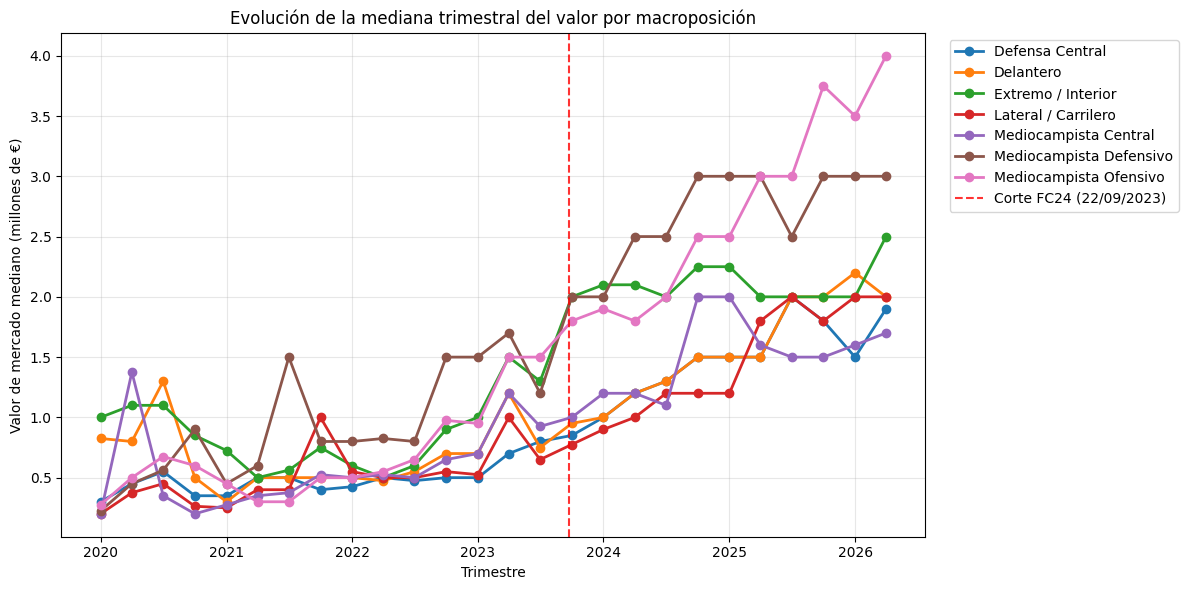

In [77]:
plt.figure(figsize=(12, 6))

for posicion in serie_trimestral.columns:
    plt.plot(
        serie_trimestral.index,
        serie_trimestral[posicion] / 1_000_000,
        marker='o',
        linewidth=2,
        label=posicion
    )

plt.axvline(
    pd.Timestamp('2023-09-22'),
    color='red',
    linestyle='--',
    alpha=0.8,
    label='Corte FC24 (22/09/2023)'
)

plt.title(
    'Evolución de la mediana trimestral del valor por macroposición'
)
plt.xlabel('Trimestre')
plt.ylabel('Valor de mercado mediano (millones de €)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación:** Desde 2023 se observa una tendencia general de crecimiento en la mediana del valor de mercado. Los mediocampistas ofensivos presentan el mayor aumento y alcanzan aproximadamente €4 millones en 2026, seguidos por los mediocampistas defensivos con cerca de €3 millones.

Las demás posiciones muestran crecimientos más moderados y algunos periodos de estabilidad. La evolución corresponde a medianas agregadas de la cohorte analizada y no implica que todos los jugadores de una posición se revaloricen de la misma manera.

## Evaluación temporal del pronóstico

Para evaluar el pronóstico se reservan los últimos cuatro trimestres de cada serie como conjunto de prueba. Los trimestres anteriores se utilizan para entrenamiento.

Se comparan dos alternativas:

- **Modelo base:** repite el último valor conocido del entrenamiento.
- **Holt con tendencia amortiguada:** estima una tendencia que pierde intensidad gradualmente.

Se utilizan MAE y RMSE expresados en millones de euros. El mejor modelo para cada posición será el que obtenga el menor RMSE en los cuatro trimestres reservados.

In [78]:
from statsmodels.tsa.holtwinters import Holt
from sklearn.metrics import mean_absolute_error, mean_squared_error

serie_trimestral = serie_trimestral.asfreq('QS')
horizonte_prueba = 4
resultados_forecast = []

for posicion in serie_trimestral.columns:

    serie = serie_trimestral[posicion].astype(float)

    entrenamiento = serie.iloc[:-horizonte_prueba]
    prueba = serie.iloc[-horizonte_prueba:]

    prediccion_base = np.repeat(
        entrenamiento.iloc[-1],
        horizonte_prueba
    )

    modelo_holt = Holt(
        entrenamiento,
        damped_trend=True,
        initialization_method='estimated'
    ).fit(optimized=True)

    prediccion_holt = modelo_holt.forecast(horizonte_prueba)

    mae_base = mean_absolute_error(
        prueba,
        prediccion_base
    )

    rmse_base = np.sqrt(
        mean_squared_error(
            prueba,
            prediccion_base
        )
    )

    mae_holt = mean_absolute_error(
        prueba,
        prediccion_holt
    )

    rmse_holt = np.sqrt(
        mean_squared_error(
            prueba,
            prediccion_holt
        )
    )

    mejor_modelo = (
        'Holt'
        if rmse_holt < rmse_base
        else 'Base'
    )

    resultados_forecast.append({
        'macro_posicion': posicion,
        'MAE_base_millones': mae_base / 1_000_000,
        'RMSE_base_millones': rmse_base / 1_000_000,
        'MAE_Holt_millones': mae_holt / 1_000_000,
        'RMSE_Holt_millones': rmse_holt / 1_000_000,
        'mejor_modelo': mejor_modelo
    })

metricas_forecast = pd.DataFrame(resultados_forecast)

display(
    metricas_forecast.round(3)
)

,macro_posicion,MAE_base_millones,RMSE_base_millones,MAE_Holt_millones,RMSE_Holt_millones,mejor_modelo
0,Defensa Central,0.300,0.354,0.246,0.271,Holt
1,Delantero,0.550,0.557,0.359,0.371,Holt
2,Extremo / Interior,0.125,0.250,0.157,0.267,Base
3,Lateral / Carrilero,0.150,0.173,0.634,0.640,Base
4,Mediocampista Central,0.075,0.087,0.592,0.597,Base
5,Mediocampista Defensivo,0.125,0.250,0.811,0.825,Base
6,Mediocampista Ofensivo,0.562,0.673,0.202,0.227,Holt


**Interpretación:** El modelo base obtuvo menor RMSE en extremo/interior, lateral/carrilero, mediocampista central y mediocampista defensivo. Holt fue superior en defensa central, delantero y mediocampista ofensivo.

El menor error seleccionado corresponde a mediocampista central, con un RMSE aproximado de €0.087 millones usando el modelo base. El mayor RMSE entre los modelos elegidos corresponde a delantero, con aproximadamente €0.371 millones utilizando Holt.

Los resultados confirman que un modelo con tendencia no siempre supera una referencia sencilla. La corrección mediante snapshots redujo los errores y produjo series más representativas, aunque los pronósticos continúan siendo agregados por posición y no predicciones individuales.

## Pronóstico trimestral por macroposición

Cada serie se vuelve a entrenar utilizando los 26 trimestres disponibles. Para cada macroposición se utiliza el modelo que obtuvo el menor RMSE durante la evaluación temporal.

El horizonte es de cuatro trimestres. Los resultados representan la mediana esperada del valor de mercado por posición y no una predicción individual para cada jugador.

In [79]:
horizonte_futuro = 4
pronosticos = []

ultimo_periodo = serie_trimestral.index[-1].to_period('Q')

fechas_futuras = pd.DatetimeIndex([
    (ultimo_periodo + i).start_time
    for i in range(1, horizonte_futuro + 1)
])

for posicion in serie_trimestral.columns:

    serie = serie_trimestral[posicion].astype(float)

    modelo_seleccionado = (
        metricas_forecast
        .set_index('macro_posicion')
        .loc[posicion, 'mejor_modelo']
    )

    if modelo_seleccionado == 'Holt':

        modelo_final = Holt(
            serie,
            damped_trend=True,
            initialization_method='estimated'
        ).fit(optimized=True)

        valores_futuros = modelo_final.forecast(
            horizonte_futuro
        ).values

    else:

        valores_futuros = np.repeat(
            serie.iloc[-1],
            horizonte_futuro
        )

    for fecha, valor in zip(
        fechas_futuras,
        valores_futuros
    ):
        pronosticos.append({
            'macro_posicion': posicion,
            'trimestre': fecha,
            'modelo_seleccionado': modelo_seleccionado,
            'valor_pronosticado_eur': valor
        })

pronostico_posiciones = pd.DataFrame(pronosticos)

display(
    pronostico_posiciones.assign(
        valor_pronosticado_millones=lambda tabla:
        tabla['valor_pronosticado_eur'] / 1_000_000
    )[
        [
            'macro_posicion',
            'trimestre',
            'modelo_seleccionado',
            'valor_pronosticado_millones'
        ]
    ].round(3)
)

,macro_posicion,trimestre,modelo_seleccionado,valor_pronosticado_millones
0,Defensa Central,2026-07-01,Holt,1.853
1,Defensa Central,2026-10-01,Holt,1.877
2,Defensa Central,2027-01-01,Holt,1.900
3,Defensa Central,2027-04-01,Holt,1.920
4,Delantero,2026-07-01,Holt,2.264
5,Delantero,2026-10-01,Holt,2.363
6,Delantero,2027-01-01,Holt,2.457
7,Delantero,2027-04-01,Holt,2.547
8,Extremo / Interior,2026-07-01,Base,2.500
9,Extremo / Interior,2026-10-01,Base,2.500


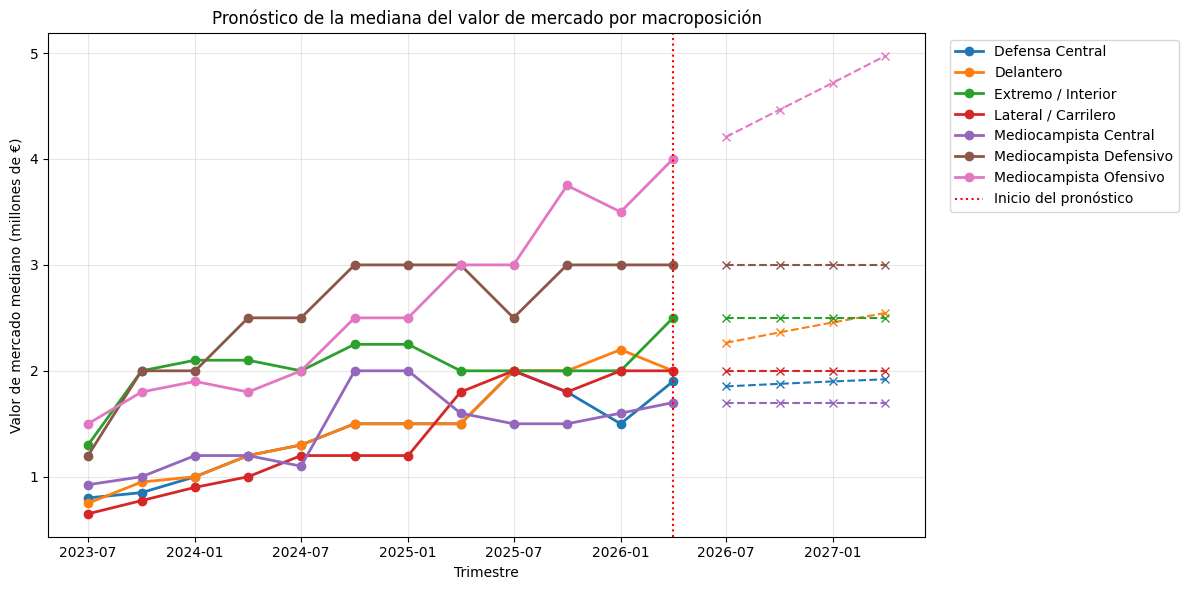

In [80]:
plt.figure(figsize=(12, 6))

for posicion in serie_trimestral.columns:

    historial = serie_trimestral[posicion].iloc[-12:]

    linea, = plt.plot(
        historial.index,
        historial / 1_000_000,
        marker='o',
        linewidth=2,
        label=posicion
    )

    futuro = pronostico_posiciones[
        pronostico_posiciones['macro_posicion'] == posicion
    ]

    plt.plot(
        futuro['trimestre'],
        futuro['valor_pronosticado_eur'] / 1_000_000,
        linestyle='--',
        marker='x',
        color=linea.get_color()
    )

plt.axvline(
    serie_trimestral.index[-1],
    color='red',
    linestyle=':',
    label='Inicio del pronóstico'
)

plt.title(
    'Pronóstico de la mediana del valor de mercado por macroposición'
)
plt.xlabel('Trimestre')
plt.ylabel('Valor de mercado mediano (millones de €)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación:** Holt proyecta crecimiento en defensa central, delantero y mediocampista ofensivo. La mayor variación corresponde al mediocampista ofensivo, cuya mediana aumentaría de €4.21 a €4.97 millones, aproximadamente 18.2%. En delanteros aumentaría de €2.26 a €2.55 millones, cerca de 12.5%, mientras que defensa central crecería aproximadamente 3.6%.

En extremo/interior, lateral/carrilero, mediocampista central y defensivo, el modelo base presentó menor error, por lo que sus medianas permanecen constantes. Los resultados representan tendencias agregadas por posición y no retornos garantizados para jugadores individuales.

## Exportación de resultados temporales

Se exportan las series trimestrales corregidas, las métricas de evaluación y los pronósticos por macroposición para su integración en Power BI.

In [81]:
from pathlib import Path

carpeta_series = (
    Path(carpeta_salida)
    / 'series_temporales'
)

carpeta_series.mkdir(
    parents=True,
    exist_ok=True
)

serie_trimestral.reset_index().to_csv(
    carpeta_series / 'series_trimestrales_posicion.csv',
    index=False,
    encoding='utf-8-sig'
)

metricas_forecast.to_csv(
    carpeta_series / 'metricas_forecast_posicion.csv',
    index=False,
    encoding='utf-8-sig'
)

pronostico_posiciones.to_csv(
    carpeta_series / 'pronostico_posiciones.csv',
    index=False,
    encoding='utf-8-sig'
)

print('Archivos temporales exportados:')
print('- series_trimestrales_posicion.csv')
print('- metricas_forecast_posicion.csv')
print('- pronostico_posiciones.csv')

Archivos temporales exportados:
- series_trimestrales_posicion.csv
- metricas_forecast_posicion.csv
- pronostico_posiciones.csv


## ROI histórico a doce meses por posición

Se compara el valor más cercano al 22/09/2023 con una valorización registrada aproximadamente doce meses después. El ROI representa la variación porcentual del valor de mercado. Para el gráfico solo se consideran posiciones con al menos diez jugadores.

Jugadores con valor base T0 válido (180 días previos): 498
Jugadores con seguimiento completo a ~12 meses (T0 y T1): 442

=== ROI HISTÓRICO A 12 MESES POR POSICIÓN PRINCIPAL ===


,pos_principal,jugadores,mediana_valor_t0,mediana_valor_t1,mediana_roi_12m_pct,promedio_roi_12m_pct,pct_jugadores_revalorizados
12,RWB,4,250000.0,800000.0,175.00,329.17,100.00
8,LWB,6,425000.0,1100000.0,131.67,488.06,83.33
1,CB,69,800000.0,1500000.0,87.50,325.72,72.46
5,LB,28,825000.0,1750000.0,71.57,172.68,67.86
2,CDM,37,1200000.0,2500000.0,66.67,148.52,64.86
7,LW,16,3250000.0,5250000.0,60.00,286.09,81.25
13,ST,63,950000.0,1300000.0,48.00,165.60,61.90
4,CM,46,1000000.0,2000000.0,47.73,152.24,67.39
10,RM,46,1350000.0,1650000.0,35.42,134.78,63.04
9,RB,32,550000.0,1200000.0,26.67,235.15,56.25


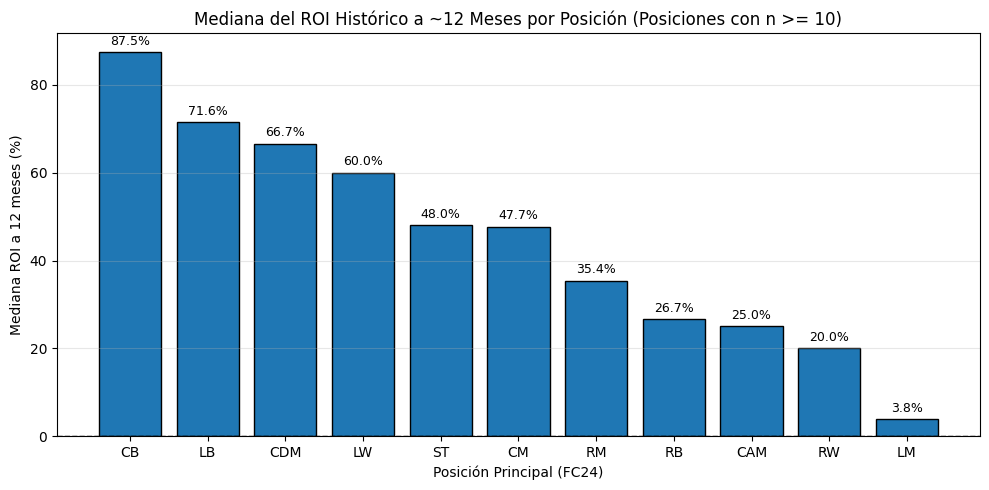

In [82]:
fecha_corte = pd.Timestamp('2023-09-22')
inicio_t0 = fecha_corte - pd.Timedelta(days=180)

t0_df = ts_latam[ts_latam['date'].between(inicio_t0, fecha_corte)].copy()
t0_df = (
    t0_df.sort_values(['player_id_tm', 'date'], ascending=[True, False])
    .drop_duplicates('player_id_tm', keep='first')
    .rename(columns={'market_value_in_eur': 'valor_t0', 'date': 'fecha_t0'})
    [['player_id_tm', 'fecha_t0', 'valor_t0']]
)

fecha_t1_obj = fecha_corte + pd.Timedelta(days=365)
inicio_t1 = fecha_t1_obj - pd.Timedelta(days=90)
fin_t1 = fecha_t1_obj + pd.Timedelta(days=90)

t1_df = ts_latam[ts_latam['date'].between(inicio_t1, fin_t1)].copy()
t1_df['dist_t1'] = (t1_df['date'] - fecha_t1_obj).abs()
t1_df = (
    t1_df.sort_values(['player_id_tm', 'dist_t1', 'date'], ascending=[True, True, False])
    .drop_duplicates('player_id_tm', keep='first')
    .rename(columns={'market_value_in_eur': 'valor_t1', 'date': 'fecha_t1'})
    [['player_id_tm', 'fecha_t1', 'valor_t1']]
)

df_roi = (
    df_cruzado[['player_id_fc24', 'player_id_tm', 'short_name', 'long_name', 'nationality_name',
                'club_name', 'age', 'pos_principal', 'macro_posicion', 'overall', 'potential']]
    .merge(t0_df, on='player_id_tm', how='inner')
    .merge(t1_df, on='player_id_tm', how='left')
)

df_roi['potential_gap'] = df_roi['potential'] - df_roi['overall']
df_roi['roi_12m_pct'] = ((df_roi['valor_t1'] - df_roi['valor_t0']) / df_roi['valor_t0']) * 100

df_roi_valido = df_roi[df_roi['roi_12m_pct'].notna()].copy()

print(f"Jugadores con valor base T0 válido (180 días previos): {len(df_roi)}")
print(f"Jugadores con seguimiento completo a ~12 meses (T0 y T1): {len(df_roi_valido)}")

resumen_roi_pos = (
    df_roi_valido
    .groupby('pos_principal')
    .agg(
        jugadores=('player_id_tm', 'count'),
        mediana_valor_t0=('valor_t0', 'median'),
        mediana_valor_t1=('valor_t1', 'median'),
        mediana_roi_12m_pct=('roi_12m_pct', 'median'),
        promedio_roi_12m_pct=('roi_12m_pct', 'mean'),
        pct_jugadores_revalorizados=('roi_12m_pct', lambda x: (x > 0).mean() * 100)
    )
    .reset_index()
    .sort_values('mediana_roi_12m_pct', ascending=False)
)

print("\n=== ROI HISTÓRICO A 12 MESES POR POSICIÓN PRINCIPAL ===")
display(resumen_roi_pos.round(2))

pos_filtradas = resumen_roi_pos[resumen_roi_pos['jugadores'] >= 10]

plt.figure(figsize=(10, 5))
barras = plt.bar(pos_filtradas['pos_principal'], pos_filtradas['mediana_roi_12m_pct'], color='#1f77b4', edgecolor='black')
plt.axhline(0, color='black', linewidth=1, linestyle='--')
plt.title('Mediana del ROI Histórico a ~12 Meses por Posición (Posiciones con n >= 10)')
plt.xlabel('Posición Principal (FC24)')
plt.ylabel('Mediana ROI a 12 meses (%)')
plt.grid(axis='y', alpha=0.3)

for barra in barras:
    yval = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2, yval + (1 if yval >= 0 else -4), f"{yval:.1f}%", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

**Interpretación:** Defensa central registró la mayor mediana de ROI histórico, con 87.5%, seguida por lateral izquierdo con 71.6% y mediocampista defensivo con 66.7%. En contraste, mediocampista izquierdo presentó el menor crecimiento, con 3.8%. Estos resultados son históricos y no garantizan retornos futuros.

## Señales de subvaloración y contexto de pronóstico por posición

Los candidatos se identifican mediante su valor frente a pares comparables, brecha de potencial y edad. El forecast por macroposición se utiliza como contexto adicional y no como una predicción individual garantizada.

In [83]:
df_roi['banda_overall'] = pd.cut(
    df_roi['overall'],
    bins=[0, 64, 69, 74, 79, 100],
    labels=[
        '<=64',
        '65-69',
        '70-74',
        '75-79',
        '80+'
    ]
)

df_roi['mediana_pares_t0'] = (
    df_roi
    .groupby(
        ['macro_posicion', 'banda_overall'],
        observed=True
    )['valor_t0']
    .transform('median')
)

df_roi['ratio_valor_pares'] = (
    df_roi['valor_t0']
    / df_roi['mediana_pares_t0']
)

ultimo_valor_historico = (
    serie_trimestral
    .iloc[-1]
    .rename('valor_posicion_actual')
)

ultimo_pronostico = (
    pronostico_posiciones
    .sort_values('trimestre')
    .groupby('macro_posicion')
    .tail(1)
    .set_index('macro_posicion')[
        'valor_pronosticado_eur'
    ]
    .rename('valor_posicion_pronosticado')
)

contexto_pronostico_posicion = pd.concat(
    [
        ultimo_valor_historico,
        ultimo_pronostico
    ],
    axis=1
).dropna().reset_index()

contexto_pronostico_posicion[
    'crecimiento_pronosticado_posicion_pct'
] = (
    (
        contexto_pronostico_posicion[
            'valor_posicion_pronosticado'
        ]
        / contexto_pronostico_posicion[
            'valor_posicion_actual'
        ]
    ) - 1
) * 100

df_roi = df_roi.drop(
    columns=[
        'crecimiento_pronosticado_posicion_pct'
    ],
    errors='ignore'
)

df_roi = df_roi.merge(
    contexto_pronostico_posicion[
        [
            'macro_posicion',
            'crecimiento_pronosticado_posicion_pct'
        ]
    ],
    on='macro_posicion',
    how='left'
)

candidatos_inversion = df_roi[
    (df_roi['ratio_valor_pares'] < 0.75)
    & (df_roi['potential_gap'] >= 8)
    & (df_roi['age'] <= 22)
].copy()

candidatos_inversion = (
    candidatos_inversion
    .sort_values(
        [
            'ratio_valor_pares',
            'potential_gap',
            'crecimiento_pronosticado_posicion_pct'
        ],
        ascending=[True, False, False]
    )
)

print(
    'Candidatos prioritarios detectados:',
    len(candidatos_inversion)
)

columnas_reporte = [
    'short_name',
    'nationality_name',
    'club_name',
    'age',
    'pos_principal',
    'macro_posicion',
    'overall',
    'potential',
    'potential_gap',
    'valor_t0',
    'mediana_pares_t0',
    'ratio_valor_pares',
    'crecimiento_pronosticado_posicion_pct',
    'roi_12m_pct'
]

display(
    candidatos_inversion[
        columnas_reporte
    ].head(15).round(2)
)

Candidatos prioritarios detectados: 119


,short_name,nationality_name,club_name,age,pos_principal,macro_posicion,overall,potential,potential_gap,valor_t0,mediana_pares_t0,ratio_valor_pares,crecimiento_pronosticado_posicion_pct,roi_12m_pct
442,P. Tanda,Argentina,Unión Santa Fe,21,CDM,Mediocampista Defensivo,62,71,9,25000,500000.0,0.05,0.00,200.0
255,N. Paz,Argentina,Unión Santa Fe,20,CB,Defensa Central,67,75,8,50000,800000.0,0.06,1.06,3300.0
371,M. Del Blanco,Argentina,Unión Santa Fe,19,LWB,Lateral / Carrilero,64,77,13,25000,325000.0,0.08,0.00,2100.0
423,J. Panichelli,Argentina,Deportivo Alavés,20,ST,Delantero,62,79,17,25000,300000.0,0.08,27.33,2300.0
466,M. Hernandez,Argentina,San Lorenzo,18,ST,Delantero,60,74,14,25000,300000.0,0.08,27.33,NaN
478,E. Viveros,Argentina,Arsenal de Sarandi,20,RM,Extremo / Interior,59,71,12,25000,300000.0,0.08,0.00,1300.0
471,C. Paraco,Venezuela,Deportivo Táchira,19,LM,Extremo / Interior,60,69,9,25000,300000.0,0.08,0.00,1100.0
482,A. Riep,Chile,Audax Italiano,19,RM,Extremo / Interior,59,68,9,25000,300000.0,0.08,0.00,2300.0
416,M. Brondo,Argentina,Barracas Central,21,ST,Delantero,63,71,8,25000,300000.0,0.08,27.33,NaN
413,M. Puig,Argentina,Barracas Central,22,CDM,Mediocampista Defensivo,63,72,9,50000,500000.0,0.10,0.00,0.0


**Interpretación:** Se identificaron 119 candidatos menores de 23 años, con una brecha de potencial mínima de 8 puntos y un valor inferior al 75% de la mediana de sus pares. Los primeros casos presentan ratios entre 0.05 y 0.15, lo que indica valores considerablemente inferiores a jugadores de posición y overall similares.

El crecimiento pronosticado corresponde a la macroposición y no al jugador individual. Los casos con valores de €25,000 o €50,000 deben revisarse manualmente porque pueden representar valorizaciones mínimas, jugadores con poca exposición o registros que requieren validación adicional.

## Principales candidatos según descuento frente a pares

Se muestran los diez candidatos con menor ratio de valor frente a pares. Las etiquetas incorporan su brecha de potencial y el crecimiento pronosticado de su macroposición.

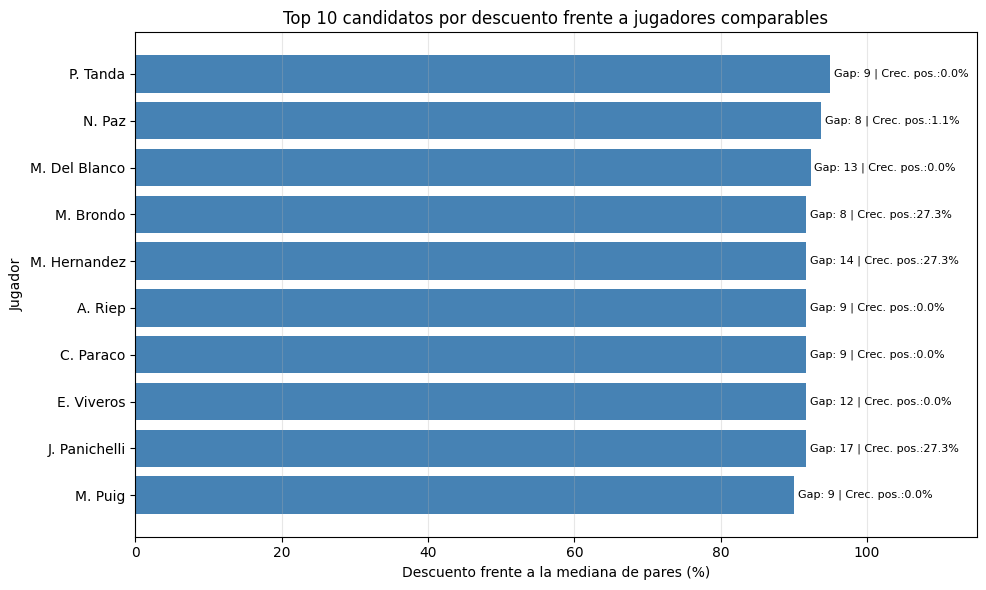

In [84]:
top10_candidatos = (
    candidatos_inversion
    .head(10)
    .copy()
)

top10_candidatos[
    'descuento_frente_pares_pct'
] = (
    1 - top10_candidatos['ratio_valor_pares']
) * 100

top10_grafico = (
    top10_candidatos
    .sort_values('descuento_frente_pares_pct')
)

plt.figure(figsize=(10, 6))

barras = plt.barh(
    top10_grafico['short_name'],
    top10_grafico['descuento_frente_pares_pct'],
    color='steelblue'
)

for barra, (_, jugador) in zip(
    barras,
    top10_grafico.iterrows()
):
    plt.text(
        barra.get_width() + 0.5,
        barra.get_y() + barra.get_height() / 2,
        (
            f"Gap: {jugador['potential_gap']} | "
            f"Crec. pos.:{jugador['crecimiento_pronosticado_posicion_pct']:.1f}%"
        ),
        va='center',
        fontsize=8
    )

plt.title(
    'Top 10 candidatos por descuento frente a jugadores comparables'
)
plt.xlabel('Descuento frente a la mediana de pares (%)')
plt.ylabel('Jugador')
plt.xlim(0, 115)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación:** Los diez candidatos presentan descuentos aproximados de 85% a 95% frente a la mediana de jugadores comparables. P. Tanda, N. Paz y M. Del Blanco muestran los mayores descuentos relativos.

J. Panichelli y M. Hernández combinan un descuento cercano al 92%, una brecha de potencial alta y una proyección favorable para la posición de delantero. Estas señales permiten priorizar su revisión, pero deben complementarse con validación deportiva, fecha de valorización y calidad del matching antes de recomendar una inversión.

## Clustering y segmentación de perfiles

Se aplica K-Means utilizando exclusivamente edad, nivel actual, brecha de potencial y atributos deportivos. El valor de mercado y el ratio frente a pares no intervienen en la formación de los grupos; se utilizan posteriormente para describir los perfiles obtenidos.

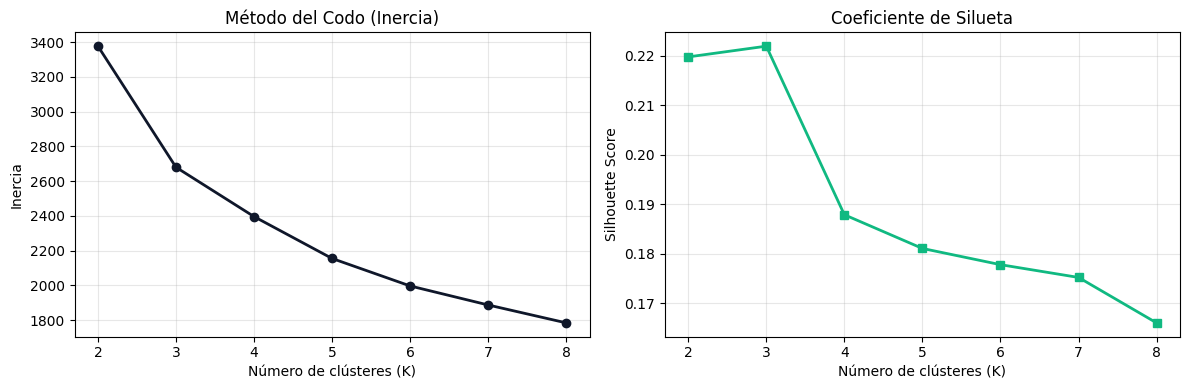

,K,Inercia,Silhouette_Score
0,2,3376.60,0.2197
1,3,2679.97,0.2219
2,4,2396.12,0.1879
3,5,2155.17,0.1811
4,6,1997.11,0.1778
5,7,1887.60,0.1752
6,8,1784.67,0.1660


In [85]:
from pathlib import Path
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from google.colab import files

if 'carpeta_salida' in globals():
    carpeta_clustering = Path(carpeta_salida) / 'clustering_segmentacion'
elif Path('/content/drive/MyDrive').exists():
    carpeta_clustering = Path('/content/drive/MyDrive/Caso_C_Grupo4/clustering_segmentacion')
else:
    carpeta_clustering = Path.cwd() / 'resultados_clustering'
carpeta_clustering.mkdir(parents=True, exist_ok=True)

if 'analisis_pc1' not in globals():
    raise RuntimeError('Ejecuta primero las celdas iniciales que crean analisis_pc1.')

base_cluster = analisis_pc1.copy().reset_index(drop=True)
base_cluster['market_value_in_eur'] = pd.to_numeric(base_cluster['market_value_in_eur'], errors='coerce')
base_cluster = base_cluster[
    base_cluster['market_value_in_eur'].gt(0) & np.isfinite(base_cluster['market_value_in_eur'])
].copy().reset_index(drop=True)

base_cluster['log_valor_mercado'] = np.log10(base_cluster['market_value_in_eur'])
if 'potential_gap' not in base_cluster.columns:
    base_cluster['potential_gap'] = base_cluster['potential'] - base_cluster['overall']

vars_cluster = [
    'age',
    'overall',
    'potential_gap',
    'pace',
    'shooting',
    'passing',
    'dribbling',
    'defending',
    'physic'
]

base_cluster[vars_cluster] = base_cluster[vars_cluster].apply(pd.to_numeric, errors='coerce')
base_cluster = base_cluster.dropna(subset=vars_cluster).copy().reset_index(drop=True)

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(base_cluster[vars_cluster])

inercias = []
siluetas = []
rango_k = range(2, 9)

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    etiquetas = km.fit_predict(X_cluster_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_cluster_scaled, etiquetas))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rango_k, inercias, marker='o', color='#0F172A', linewidth=2)
ax[0].set(title='Método del Codo (Inercia)', xlabel='Número de clústeres (K)', ylabel='Inercia')
ax[0].grid(True, alpha=0.3)

ax[1].plot(rango_k, siluetas, marker='s', color='#10B981', linewidth=2)
ax[1].set(title='Coeficiente de Silueta', xlabel='Número de clústeres (K)', ylabel='Silhouette Score')
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(carpeta_clustering / 'seleccion_k_codo_silueta.png', dpi=160, bbox_inches='tight')
plt.show()

metricas_k = pd.DataFrame({
    'K': list(rango_k),
    'Inercia': np.round(inercias, 2),
    'Silhouette_Score': np.round(siluetas, 4)
})
display(metricas_k)

**Interpretación:** K=3 obtiene el mayor coeficiente de silueta, con 0.2219, y presenta una reducción importante de la inercia frente a K=2. Por ello, se seleccionan tres clusters.

El silhouette continúa siendo relativamente bajo, lo que indica que los perfiles se superponen y no forman grupos completamente separados. En consecuencia, los clusters se interpretan como arquetipos exploratorios de scouting y no como categorías naturales o definitivas.

## 1. Entrenamiento del modelo K-Means y perfilamiento de arquetipos

Se entrena el modelo final con K = 3 segmentos, seleccionado por presentar el mayor coeficiente de silueta y una reducción relevante de la inercia.

,cluster_id,jugadores,edad_prom,overall_prom,potential_prom,brecha_potencial,mediana_valor_eur,ratio_pares_prom,ritmo_prom,tiro_prom,pase_prom,regate_prom,defensa_prom,fisico_prom
0,0,132,21.38,65.85,75.48,9.63,550000.0,1.48,65.36,36.58,50.55,54.92,64.45,67.62
1,1,189,22.03,70.90,78.51,7.61,2500000.0,1.39,75.82,62.37,64.39,71.62,48.22,64.10
2,2,177,19.77,64.17,76.50,12.33,550000.0,2.28,71.27,57.05,56.76,65.41,38.45,54.78


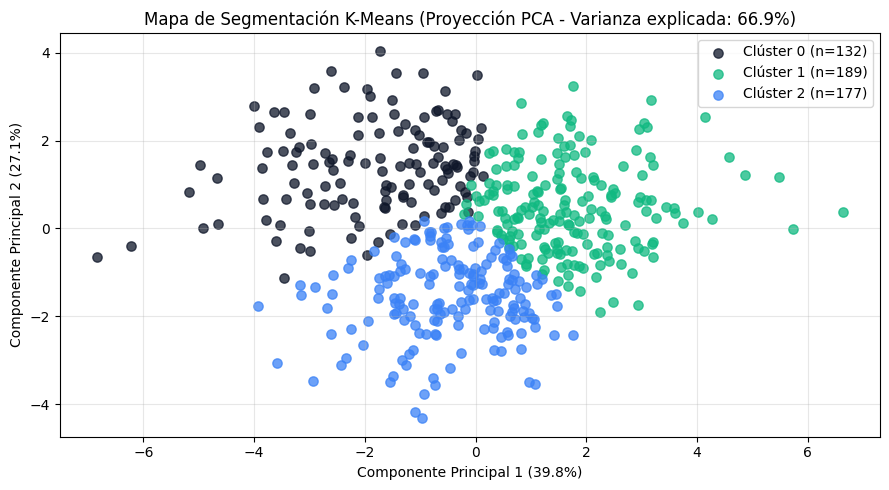

In [86]:
from sklearn.decomposition import PCA

k_optimo = 3
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=20)
base_cluster['cluster_id'] = kmeans_final.fit_predict(X_cluster_scaled)

perfil_clusters = base_cluster.groupby('cluster_id').agg(
    jugadores=('player_id_fc24', 'count'),
    edad_prom=('age', 'mean'),
    overall_prom=('overall', 'mean'),
    potential_prom=('potential', 'mean'),
    brecha_potencial=('potential_gap', 'mean'),
    mediana_valor_eur=('market_value_in_eur', 'median'),
    ratio_pares_prom=('ratio_valor_vs_pares', 'mean'),
    ritmo_prom=('pace', 'mean'),
    tiro_prom=('shooting', 'mean'),
    pase_prom=('passing', 'mean'),
    regate_prom=('dribbling', 'mean'),
    defensa_prom=('defending', 'mean'),
    fisico_prom=('physic', 'mean')
).round(2).reset_index()

display(perfil_clusters)

pca = PCA(n_components=2, random_state=42)
coords_pca = pca.fit_transform(X_cluster_scaled)
base_cluster['pca_1'] = coords_pca[:, 0]
base_cluster['pca_2'] = coords_pca[:, 1]

plt.figure(figsize=(9, 5))
colores = ['#0F172A', '#10B981', '#3B82F6', '#F59E0B']
for cid in sorted(base_cluster['cluster_id'].unique()):
    sub = base_cluster[base_cluster['cluster_id'] == cid]
    plt.scatter(sub['pca_1'], sub['pca_2'], label=f'Clúster {cid} (n={len(sub)})', alpha=0.75, s=45, color=colores[cid % len(colores)])

plt.title(f'Mapa de Segmentación K-Means (Proyección PCA - Varianza explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%)')
plt.xlabel(f'Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(carpeta_clustering / 'mapa_pca_clusters.png', dpi=160, bbox_inches='tight')
plt.show()

**Interpretación:** El cluster 0 reúne 132 jugadores con mayor orientación defensiva y física. El cluster 1 contiene 189 jugadores con mayor overall y mejores atributos técnicos y ofensivos. El cluster 2 agrupa 177 futbolistas más jóvenes y con la mayor brecha de potencial, por lo que representa perfiles en desarrollo.

Los dos componentes del PCA conservan 66.9% de la variación. Existe superposición entre los grupos, coherente con el silhouette de 0.2219; por ello, los clusters se utilizan como arquetipos exploratorios y no como categorías definitivas. El valor de mercado y el ratio frente a pares se emplean únicamente para describir los grupos después de formarlos.

## 2. Etiquetado de negocio, sensibilidad y exportación para Power BI

Se asignan etiquetas según los perfiles deportivos y se evalúa la sensibilidad con K ∈ {2, 3, 4}. Finalmente, se exportan los resultados para Power BI.

In [87]:
mapa_nombres_cluster = {
    0: '1. Perfil Defensivo y Físico',
    1: '2. Talento Técnico Consolidado',
    2: '3. Prospectos Jóvenes en Desarrollo'
}

base_cluster['segmento_scouting'] = (
    base_cluster['cluster_id']
    .map(mapa_nombres_cluster)
)

perfil_clusters['segmento_scouting'] = (
    perfil_clusters['cluster_id']
    .map(mapa_nombres_cluster)
)

filas_sensibilidad = []

for k_test in [2, 3, 4]:

    km_t = KMeans(
        n_clusters=k_test,
        random_state=42,
        n_init=20
    )

    etiquetas_t = km_t.fit_predict(
        X_cluster_scaled
    )

    conteos = (
        pd.Series(etiquetas_t)
        .value_counts()
    )

    filas_sensibilidad.append({
        'K_evaluado': k_test,
        'Inercia': round(km_t.inertia_, 2),
        'Silhouette_Score': round(
            silhouette_score(
                X_cluster_scaled,
                etiquetas_t
            ),
            4
        ),
        'Tamano_grupo_min': int(conteos.min()),
        'Tamano_grupo_max': int(conteos.max())
    })

sensibilidad_clusters = pd.DataFrame(
    filas_sensibilidad
)

display(sensibilidad_clusters)

columnas_jugadores_cluster = [
    'player_id_fc24',
    'long_name',
    'nationality_name',
    'club_name',
    'age',
    'posicion_agrupada',
    'overall',
    'potential',
    'potential_gap',
    'market_value_in_eur',
    'ratio_valor_vs_pares',
    'cluster_id',
    'segmento_scouting',
    'pca_1',
    'pca_2'
]

columnas_disponibles = [
    columna
    for columna in columnas_jugadores_cluster
    if columna in base_cluster.columns
]

base_cluster[
    columnas_disponibles
].to_csv(
    carpeta_clustering
    / 'segmentacion_jugadores_clusters.csv',
    index=False,
    encoding='utf-8-sig'
)

perfil_clusters.to_csv(
    carpeta_clustering
    / 'perfiles_resumen_clusters.csv',
    index=False,
    encoding='utf-8-sig'
)

metricas_k.to_csv(
    carpeta_clustering
    / 'metricas_seleccion_k.csv',
    index=False,
    encoding='utf-8-sig'
)

sensibilidad_clusters.to_csv(
    carpeta_clustering
    / 'sensibilidad_clusters.csv',
    index=False,
    encoding='utf-8-sig'
)

print('Resultados de clustering exportados correctamente.')

display(
    base_cluster[
        [
            'long_name',
            'posicion_agrupada',
            'overall',
            'potential',
            'market_value_in_eur',
            'ratio_valor_vs_pares',
            'segmento_scouting'
        ]
    ].head(10)
)


,K_evaluado,Inercia,Silhouette_Score,Tamano_grupo_min,Tamano_grupo_max
0,2,3376.60,0.2197,220,278
1,3,2679.97,0.2219,132,189
2,4,2396.12,0.1879,113,134


Resultados de clustering exportados correctamente.


,long_name,posicion_agrupada,overall,potential,market_value_in_eur,ratio_valor_vs_pares,segmento_scouting
0,Anderson Arroyo Córdoba,Defensa,69,80,800000.0,1.230769,1. Perfil Defensivo y Físico
1,Erick Daniel Sánchez Ocegueda,Mediocampo,75,79,8000000.0,0.941176,2. Talento Técnico Consolidado
2,Jaminton Leandro Campaz,Mediocampo,74,81,4000000.0,1.142857,2. Talento Técnico Consolidado
3,Javier Adolfo Altamirano Altamirano,Mediocampo,71,74,2000000.0,0.571429,2. Talento Técnico Consolidado
4,Vinícius José Paixão de Oliveira Júnior,Delantera,89,94,150000000.0,1.200000,2. Talento Técnico Consolidado
5,Nicolás Esteban Fernández Muñoz,Defensa,64,71,550000.0,2.000000,1. Perfil Defensivo y Físico
6,Jader Andrés Valencia Mena,Mediocampo,67,74,450000.0,0.500000,2. Talento Técnico Consolidado
7,Edgar Joel Elizalde Ferreira,Defensa,69,75,400000.0,0.615385,1. Perfil Defensivo y Físico
8,Braian Alejandro Galván,Mediocampo,64,72,1200000.0,4.000000,2. Talento Técnico Consolidado
9,Facundo Tomás Garcés,Defensa,73,79,4500000.0,2.250000,1. Perfil Defensivo y Físico


**Interpretación:** K=3 presenta el mayor silhouette y mantiene tamaños relativamente equilibrados, entre 132 y 189 jugadores. K=2 pierde detalle y K=4 reduce la calidad de separación. Por ello, se conservan tres arquetipos, reconociendo que su separación es moderada y exploratoria.

## Resultados integrados y recomendaciones

### 1. ¿Qué atributos se relacionan con el valor de mercado?

La regresión Ridge obtuvo el mejor desempeño entre los modelos evaluados, con un R² de 0.763 en euros, un MAE aproximado de €2.41 millones y un RMSE de €9.14 millones en la muestra de prueba. Las variables con mayor importancia fueron potential y overall. Esto indica que el nivel actual y el margen de desarrollo concentran una parte importante de la información asociada con la valorización, aunque no implican causalidad ni permiten estimar precios exactos.

### 2. ¿Qué jugadores muestran señales de posible subvaloración?

La comparación inicial frente a jugadores de posición y overall similares identificó 236 señales exploratorias. Al aplicar criterios más exigentes —ratio inferior a 0.75, brecha de potencial mínima de 8 puntos y edad máxima de 22 años— se obtuvieron 119 candidatos prioritarios.

Entre los casos con mayor descuento aparecen P. Tanda, N. Paz, M. Del Blanco, J. Panichelli y M. Hernández. Estos resultados representan filtros de scouting y no recomendaciones automáticas de contratación. Los valores mínimos y casos extremos requieren revisar la fecha de valorización, identidad del jugador y contexto deportivo.

### 3. ¿Qué posiciones muestran mayor valorización histórica y perspectiva temporal?

Entre las posiciones con al menos diez jugadores, defensa central presentó una mediana histórica de ROI a doce meses de 87.5%, seguida por lateral izquierdo con 71.6% y mediocampista defensivo con 66.7%. Las posiciones con muestras pequeñas, como RWB y LWB, no se priorizan pese a sus retornos elevados.

El forecast trimestral fue evaluado reservando los últimos cuatro trimestres. Holt fue superior para defensa central, delantero y mediocampista ofensivo, mientras que el modelo base fue mejor para las demás posiciones. En el horizonte de cuatro trimestres, delantero presenta un crecimiento agregado aproximado de 27.3% y mediocampista ofensivo de 24.4%. Estas cifras corresponden a medianas por posición y no a retornos garantizados para jugadores individuales.

### 4. ¿Qué perfiles deportivos aparecen en el clustering?

El modelo K-Means seleccionó tres clusters utilizando únicamente edad, overall, brecha de potencial y atributos deportivos:

- **Perfil defensivo y físico:** 132 jugadores con mayor defensa y físico.
- **Talento técnico consolidado:** 189 jugadores con mayor overall, ritmo, pase, disparo y regate.
- **Prospectos jóvenes en desarrollo:** 177 jugadores con menor edad y mayor brecha de potencial.

K=3 obtuvo un silhouette de 0.2219. La separación es moderada, por lo que los grupos deben interpretarse como arquetipos exploratorios y no como categorías definitivas.

### 5. Respuesta a la pregunta huérfana

¿Qué jugadores de Liga 1 U23 combinan un valor inferior al de pares comparables con rendimiento destacado por 90 minutos?

Las 60 fichas jugador-partido permitieron contrastar ocho jugadores mediante métricas por 90 minutos. Piero Quispe combina un ratio frente a pares de 0.286 con aproximadamente 36.99 pases, 1.38 intercepciones y 1.98 regates exitosos por 90 minutos. Anderson Villacorta presenta un ratio de 0.545, aproximadamente 39.85 pases y 2.38 intercepciones por 90 minutos. Matías Lazo combina un ratio de 0.615 con aproximadamente 37.63 pases por 90 minutos.

Estos casos muestran que el contraste con estadísticas públicas permite diferenciar jugadores que solo parecen económicos de aquellos que también presentan señales deportivas favorables. Debido a que el relevamiento contiene únicamente ocho jugadores, su resultado es exploratorio.

## Recomendaciones

1. Utilizar el ratio frente a pares, la brecha de potencial y el modelo Ridge como primer filtro cuantitativo.
2. Priorizar la revisión de candidatos con descuento elevado, potencial positivo y pertenencia a perfiles deportivos compatibles con la necesidad del club.
3. Utilizar el ROI histórico y el forecast por posición como contexto, no como promesa de retorno.
4. Validar manualmente identidad, fecha de valorización, minutos, lesiones, situación contractual y rendimiento competitivo antes de recomendar una inversión.
5. Utilizar Power BI para reducir progresivamente el universo de jugadores hasta obtener una lista corta para evaluación profesional.

## Limitaciones

Los resultados se limitan a los 580 jugadores vinculados entre FC24 y Transfermarkt, equivalentes al 54.21% del universo inicial. La base comparable contiene 498 jugadores. El error de la regresión, la antigüedad de las valorizaciones, el tamaño del relevamiento, la separación moderada de los clusters y el carácter agregado del forecast impiden interpretar los resultados como precios o retornos garantizados.

En conclusión, el proyecto proporciona un sistema de priorización reproducible que integra atributos deportivos, valorizaciones, evolución temporal, segmentación y estadísticas públicas. Su función es reducir el universo de scouting y orientar la revisión profesional, no sustituir la decisión deportiva y financiera.

# Conclusión general final

El proyecto demuestra que es posible construir un sistema analítico de scouting para priorizar jugadores latinoamericanos U23 mediante la integración de FC24, Transfermarkt, Banco Mundial y estadísticas públicas de Liga 1. De los 1,070 jugadores iniciales, se vincularon 580 con Transfermarkt y 498 obtuvieron una valorización comparable dentro de la ventana seleccionada de 180 días.

El análisis identificó 236 señales exploratorias de subvaloración y 119 candidatos que cumplen criterios más exigentes de edad, potencial y descuento frente a pares. La regresión Ridge explicó aproximadamente 76.3% de la variación del valor de mercado en la muestra de prueba, destacando overall y potential como los atributos más importantes.

El análisis histórico mostró diferencias de valorización entre posiciones. Defensa central alcanzó una mediana de ROI de 87.5%, mientras que el forecast agregado proyectó mayor crecimiento para delantero y mediocampista ofensivo. El clustering identificó tres arquetipos: perfiles defensivos y físicos, talento técnico consolidado y prospectos jóvenes en desarrollo.

El contraste con los ocho jugadores de Liga 1 permitió destacar casos como Piero Quispe, Anderson Villacorta y Matías Lazo, quienes combinan un valor inferior al de sus pares con estadísticas favorables por 90 minutos. En conjunto, los resultados permiten reducir el universo de scouting y dirigir la revisión profesional hacia candidatos con mayor interés analítico.

No obstante, las recomendaciones son exploratorias. La cobertura del matching, el error del modelo, el tamaño del relevamiento y la separación moderada de los clusters obligan a complementar los resultados con revisión deportiva, contractual, médica y financiera antes de tomar una decisión de inversión.